# Full 7,716-Compound Dataset — UMAP + DBSCAN Clustering

**Goal:** Cluster the entire 7,716-compound caspase dataset in chemical space and see:
- Which structural regions are enriched in **Active / Mixed-with-Active / Inconclusive / Inactive** compounds
- Where the **323 active compounds** (Active + Mixed-with-Active) sit relative to inactive ones
- Where the **104 fully-tested active compounds** (all 14 cell lines, active in ≥1) lie

**Pipeline**
1. ECFP4 (Morgan r=2, 2048-bit) fingerprints
2. UMAP projection (Jaccard distance) → 2D chemical space
3. k-NN elbow plot on 2D → DBSCAN
4. Cluster composition: Active / Mixed / Inconclusive / Inactive fraction per cluster
5. Overlay layers: 323 active → 104 fully-tested active
6. MCS cores + representatives for active-enriched clusters

In [24]:
import warnings
warnings.filterwarnings('ignore')

import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, rdFingerprintGenerator, rdFMCS
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import umap
import pubchempy as pcp

BASE    = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/'
RESULTS = BASE + 'results/all_cell_line_comparisions/'

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

# ── Colour palette ───────────────────────────────────────────────────────────
COLOR_MAP = {
    'Active':                       '#d62728',
    'Mixed (with Active)':          '#ff7f0e',
    'Inconclusive':                 '#9467bd',
    'Mixed (Inactive/Inconclusive)':'#8c564b',
    'Inactive':                     '#aec7e8',
}

# ── Fingerprint helpers ──────────────────────────────────────────────────────
def to_fp_matrix(mols):
    fps = [gen.GetFingerprint(m) for m in mols]
    arr = np.zeros((len(fps), 2048), dtype=np.uint8)
    for i, fp in enumerate(fps):
        DataStructs.ConvertToNumpyArray(fp, arr[i])
    return fps, arr

# ── k-NN distance plot on 2D UMAP coords ────────────────────────────────────
def knn_eps_plot(emb, min_samples, title):
    nbrs = NearestNeighbors(n_neighbors=min_samples + 1).fit(emb)
    distances, _ = nbrs.kneighbors(emb)
    sorted_d = np.sort(distances[:, -1])[::-1]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(sorted_d, 'b-', lw=1.5)
    ax.set_xlabel('Points sorted by decreasing distance')
    ax.set_ylabel(f'Euclidean dist to {min_samples}-th NN (UMAP space)')
    ax.set_title(f'{title}\nSelect eps at the knee  (min_samples={min_samples})')
    ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()
    print(f'  Min={sorted_d.min():.4f}  Median={np.median(sorted_d):.4f}  Max={sorted_d.max():.4f}')
    return sorted_d

# ── PubChem name for a single CID ────────────────────────────────────────────
def pubchem_name(cid):
    """Short human-readable name from PubChem synonyms."""
    try:
        c_ = pcp.Compound.from_cid(int(cid))
        syns = c_.synonyms or []
        short = [s for s in syns if len(s) <= 30 and s[0].isalpha()]
        name = short[0] if short else (syns[0][:28] if syns else str(cid))
        return name.title()
    except Exception:
        return str(cid)

# ── Cluster name map: most-representative CID → PubChem name ─────────────────
def get_cluster_names(dataset, clusters=None, verbose=True):
    """
    For each cluster find the compound with the highest average Tanimoto
    similarity to all cluster mates (most central representative), then
    look up its name on PubChem.  Same method as active_compounds_substructure_analysis.

    Returns  {cluster_id: name_string}
    """
    if clusters is None:
        clusters = sorted(c for c in dataset['cluster'].unique() if c != -1)
    cl_name_map = {}
    if verbose:
        print(f'Fetching PubChem names for {len(clusters)} cluster(s)...')
    for cl in clusters:
        sub = dataset[dataset['cluster'] == cl].reset_index(drop=True)
        fps = sub['fp'].tolist()
        avg = [sum(DataStructs.BulkTanimotoSimilarity(fp, fps)) for fp in fps]
        rep = sub.loc[int(np.argmax(avg))]
        cid = int(rep['PUBCHEM_CID'])
        name = pubchem_name(cid)
        cl_name_map[cl] = name
        if verbose:
            print(f'  C{cl:3d} (n={len(sub):4d})  CID {cid}  →  {name}')
    return cl_name_map

# ── MCS core (clean, drawable) ───────────────────────────────────────────────
def get_mcs_core(mols):
    mols = [m for m in mols if m is not None]
    if len(mols) < 2:
        return None
    try:
        res = rdFMCS.FindMCS(mols, ringMatchesRingOnly=True,
                             completeRingsOnly=True, timeout=10)
        if not res or not res.smartsString or res.numAtoms < 3:
            return None
        smarts_mol = Chem.MolFromSmarts(res.smartsString)
        if smarts_mol is None:
            return None
        rw = Chem.RWMol()
        for atom in smarts_mol.GetAtoms():
            rw.AddAtom(Chem.Atom(atom.GetAtomicNum() or 6))
        for bond in smarts_mol.GetBonds():
            bt = bond.GetBondType()
            if bt == Chem.BondType.UNSPECIFIED:
                bt = Chem.BondType.SINGLE
            rw.AddBond(bond.GetBeginAtomIdx(), bond.GetEndAtomIdx(), bt)
        try:
            Chem.SanitizeMol(rw)
            return rw.GetMol()
        except Exception:
            return smarts_mol
    except Exception:
        return None

# ── Pick reps closest to cluster centroid ────────────────────────────────────
def pick_central(sub, n_max=5):
    xy = sub[['umap_x', 'umap_y']].values
    dists = np.linalg.norm(xy - xy.mean(axis=0), axis=1)
    return sub.iloc[np.argsort(dists)[:n_max]]

print('Setup complete.')


Setup complete.


In [25]:
# ── Load main CSV + SMILES ───────────────────────────────────────────────────
gall = pd.read_csv(BASE + 'results/all_cell_line_comparisions/consistent_compounds_caspase_all.csv')
print(f'Main CSV: {gall.shape[0]} rows × {gall.shape[1]} cols')

ASSAY_COLS = [c for c in gall.columns if c not in ('PUBCHEM_CID', 'pattern', 'behavior')]

# Collect SMILES from all cleaned_datasets CSVs
smiles_frames = []
for fp in glob.glob(BASE + 'cleaned_datasets/*.csv'):
    try:
        tmp = pd.read_csv(fp, usecols=lambda c: c in
                          ['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'])
        if 'PUBCHEM_CID' in tmp.columns and 'PUBCHEM_EXT_DATASOURCE_SMILES' in tmp.columns:
            smiles_frames.append(tmp.dropna())
    except Exception as e:
        print(f'  skipped {os.path.basename(fp)}: {e}')

smiles_df = (pd.concat(smiles_frames, ignore_index=True)
               .drop_duplicates('PUBCHEM_CID')
               .rename(columns={'PUBCHEM_EXT_DATASOURCE_SMILES': 'SMILES'}))
print(f'SMILES pool: {len(smiles_df)} unique CIDs')

gall = gall.merge(smiles_df[['PUBCHEM_CID', 'SMILES']], on='PUBCHEM_CID', how='left')
print(f'SMILES available for {gall["SMILES"].notna().sum()} / {len(gall)} compounds')

# ── Behavior categories ──────────────────────────────────────────────────────
def assign_category(b):
    if b == 'Active':          return 'Active'
    if b == 'Inactive':        return 'Inactive'
    if b == 'Inconclusive':    return 'Inconclusive'
    if 'Active' in str(b):     return 'Mixed (with Active)'
    return 'Mixed (Inactive/Inconclusive)'

gall['behavior_category'] = gall['behavior'].apply(assign_category)
print('\nBehavior category breakdown:')
print(gall['behavior_category'].value_counts().to_string())

# ── Per-compound: number of cell lines where result = 'Active' ───────────────
gall['n_active_celllines'] = gall[ASSAY_COLS].apply(
    lambda row: (row == 'Active').sum(), axis=1)
cids_gt6 = set(gall.loc[gall['n_active_celllines'] > 6, 'PUBCHEM_CID'])
print(f'\nCompounds active in >6 cell lines: {len(cids_gt6)}')
print('Active-cell-line count distribution:')
print(gall['n_active_celllines'].value_counts().sort_index().to_string())

# ── 323 active compounds (Active + Mixed-with-Active) ────────────────────────
cids_323 = set(gall.loc[
    gall['behavior_category'].isin(['Active', 'Mixed (with Active)']),
    'PUBCHEM_CID'
])
print(f'\n323 active CIDs: {len(cids_323)}')

# ── 104 fully-tested active compounds ────────────────────────────────────────
fully_tested = gall.dropna(subset=ASSAY_COLS)
cids_104 = set(fully_tested.loc[
    fully_tested[ASSAY_COLS].isin(['Active']).any(axis=1),
    'PUBCHEM_CID'
])
print(f'104 fully-tested active CIDs: {len(cids_104)}')

# ── Parse mols + fingerprints ────────────────────────────────────────────────
gall['mol'] = gall['SMILES'].apply(
    lambda s: Chem.MolFromSmiles(str(s)) if pd.notna(s) else None)

# Keep only rows with valid mols
gvalid = gall[gall['mol'].notna()].reset_index(drop=True)
print(f'\nValid mols: {len(gvalid)} / {len(gall)}')

fps_list, fp_matrix = to_fp_matrix(gvalid['mol'].tolist())
gvalid = gvalid.copy()
gvalid['fp'] = fps_list
print('Fingerprints ready.')

Main CSV: 7716 rows × 17 cols
SMILES pool: 8777 unique CIDs
SMILES available for 7716 / 7716 compounds

Behavior category breakdown:
behavior_category
Inactive                         6967
Mixed (Inactive/Inconclusive)     359
Mixed (with Active)               257
Inconclusive                       67
Active                             66

Compounds active in >6 cell lines: 7
Active-cell-line count distribution:
n_active_celllines
0     7393
1      212
2       80
3       13
4        5
5        2
6        4
7        3
8        1
9        1
10       2

323 active CIDs: 323
104 fully-tested active CIDs: 104


[07:49:10] WARNING: not removing hydrogen atom without neighbors



Valid mols: 7716 / 7716
Fingerprints ready.


---
## Section 1 — UMAP: Full Chemical Space (all ~7K compounds)

Each point is one compound, coloured by its **behavior category**:
- Red = Active (pure)
- Orange = Mixed with Active
- Purple = Inconclusive
- Brown = Mixed (Inactive/Inconclusive)
- Light blue = Inactive

This map shows whether active compounds occupy distinct structural regions or are scattered across chemical space.

Running UMAP on 7716 compounds (this may take ~1-2 minutes)...
UMAP done.


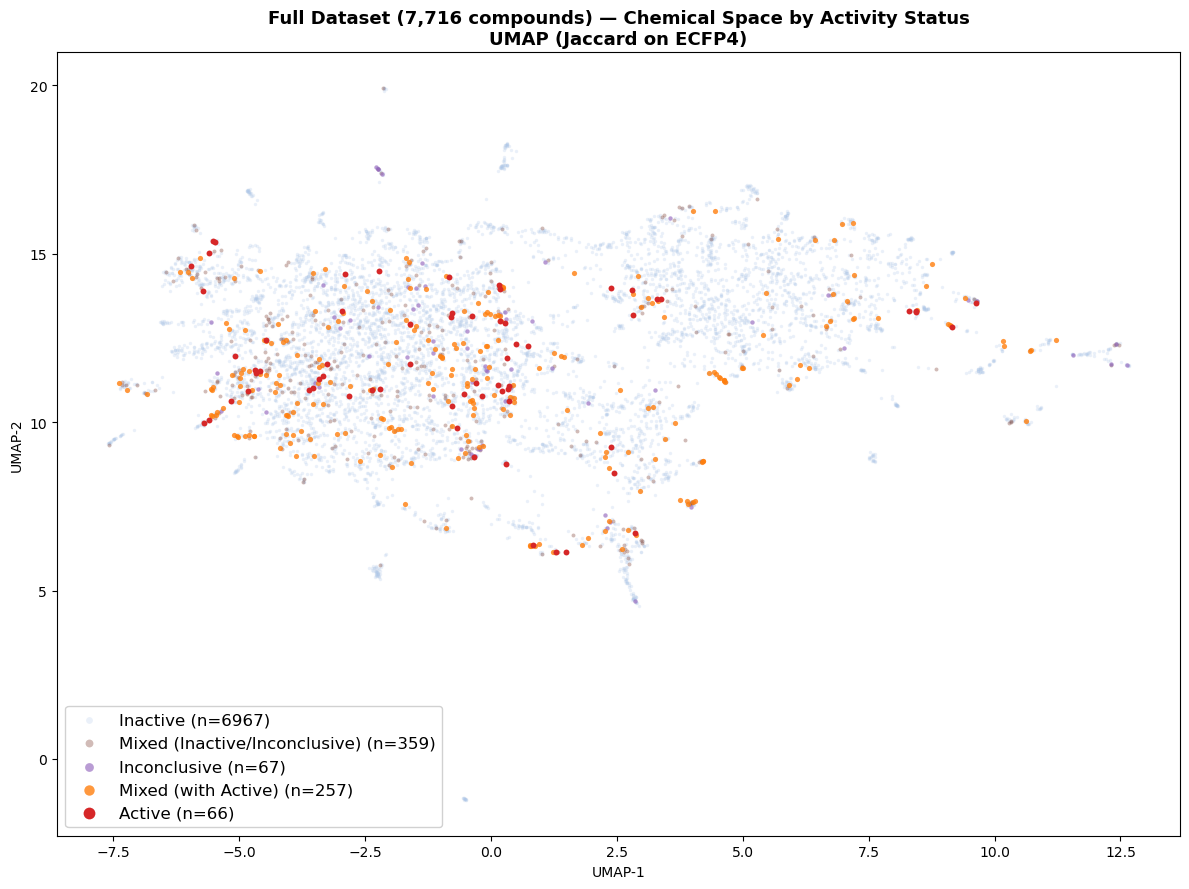

Saved → full_dataset_umap_by_behavior.png


In [26]:
print(f'Running UMAP on {len(gvalid)} compounds (this may take ~1-2 minutes)...')
reducer = umap.UMAP(
    n_neighbors=15, min_dist=0.3,
    metric='jaccard', random_state=42
)
emb_all = reducer.fit_transform(fp_matrix)
gvalid['umap_x'] = emb_all[:, 0]
gvalid['umap_y'] = emb_all[:, 1]
print('UMAP done.')

# ── Plot coloured by behavior_category ───────────────────────────────────────
# Draw Inactive first (background), then rarer categories on top
PLOT_ORDER = [
    'Inactive', 'Mixed (Inactive/Inconclusive)', 'Inconclusive',
    'Mixed (with Active)', 'Active'
]
SIZES = {
    'Inactive': 6, 'Mixed (Inactive/Inconclusive)': 8,
    'Inconclusive': 10, 'Mixed (with Active)': 14, 'Active': 18
}
ALPHAS = {
    'Inactive': 0.25, 'Mixed (Inactive/Inconclusive)': 0.4,
    'Inconclusive': 0.65, 'Mixed (with Active)': 0.8, 'Active': 1.0
}

fig, ax = plt.subplots(figsize=(12, 9))
for cat in PLOT_ORDER:
    mask = gvalid['behavior_category'] == cat
    n = mask.sum()
    ax.scatter(
        gvalid.loc[mask, 'umap_x'], gvalid.loc[mask, 'umap_y'],
        c=COLOR_MAP[cat], s=SIZES[cat], alpha=ALPHAS[cat],
        linewidths=0, label=f'{cat} (n={n})', zorder=PLOT_ORDER.index(cat)+1
    )
ax.set_title('Full Dataset (7,716 compounds) — Chemical Space by Activity Status\n'
             'UMAP (Jaccard on ECFP4)', fontsize=13, fontweight='bold')
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
ax.legend(loc='lower left', fontsize=12, markerscale=2, framealpha=0.9)
plt.tight_layout()
plt.savefig(RESULTS + 'full_dataset_umap_by_behavior.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved → full_dataset_umap_by_behavior.png')

---
## Section 2 — DBSCAN Clustering on 2D UMAP

k-NN distance plot on the 2D UMAP embedding (Euclidean) to guide `eps` selection.

**Key insight for large heterogeneous libraries:**
- The 7K compounds form one broad connected "continent" + several isolated "islands"
- `eps=0.5` → one giant cluster (the whole continent) — not useful
- `eps=0.10–0.15` → tight structural families (compounds with very similar scaffolds)
- `eps=0.20–0.25` → coarser families (same chemical class but more variation)
- Noise points = structurally unique / isolated compounds (expected and meaningful)

Adjust `EPS` after inspecting the k-NN plot below.

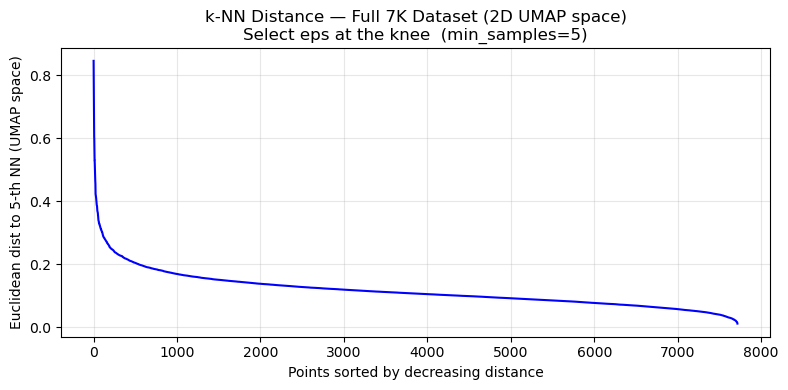

  Min=0.0111  Median=0.1065  Max=0.8453

DBSCAN (eps=0.25, min_samples=5)  →  42 clusters,  66 noise (0.9%)
NOTE: noise = structurally unique / isolated compounds (expected for a diverse library)

Top 20 clusters by size:
Cluster 1     4198
Cluster 0     1863
Cluster 2      541
Cluster 16     173
Noise           66
Cluster 17      62
Cluster 35      60
Cluster 13      53
Cluster 18      47
Cluster 8       46
Cluster 19      43
Cluster 11      41
Cluster 31      34
Cluster 26      32
Cluster 14      31
Cluster 6       30
Cluster 10      25
Cluster 22      24
Cluster 36      23
Cluster 15      22
Fetching PubChem names for 42 cluster(s)...
  C  0 (n=1863)  CID 7797  →  Ethyl Heptanoate
  C  1 (n=4198)  CID 7165  →  Ethyl Benzoate
  C  2 (n= 541)  CID 12777  →  Delta-Octanolactone
  C  3 (n=  20)  CID 454  →  Octanal
  C  4 (n=  12)  CID 2723891  →  L-Glutamic Acid Hydrochloride
  C  5 (n=  21)  CID 2519  →  Caffeine
  C  6 (n=  30)  CID 3779  →  Isoproterenol
  C  7 (n=  16)  CID 2140  →

In [27]:
# ── EPS guidance for the full 7K dataset ────────────────────────────────────
# With 7,716 compounds in a UMAP spanning ~20 units, the dataset forms one
# large connected "continent" plus a few isolated islands.
# eps=0.5 merges almost everything into one cluster — not useful.
# For a heterogeneous library at this scale, eps=0.10–0.15 finds tight
# structural families (very similar scaffolds) within the broader landscape.
# Increase to 0.20–0.25 if you want coarser, larger families.
EPS         = 0.25  
MIN_SAMPLES = 5

knn_eps_plot(emb_all, MIN_SAMPLES, 'k-NN Distance — Full 7K Dataset (2D UMAP space)')

db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(emb_all)
gvalid['cluster'] = db.labels_

n_cl    = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
n_noise = (db.labels_ == -1).sum()
N       = len(gvalid)
print(f'\nDBSCAN (eps={EPS}, min_samples={MIN_SAMPLES})'
      f'  →  {n_cl} clusters,  {n_noise} noise ({100*n_noise/N:.1f}%)')
print('NOTE: noise = structurally unique / isolated compounds (expected for a diverse library)')

# ── Cluster size table ────────────────────────────────────────────────────────
comp = gvalid.groupby('cluster').size().rename('n_compounds')
comp.index = ['Noise' if i == -1 else f'Cluster {i}' for i in comp.index]
print('\nTop 20 clusters by size:')
print(comp.sort_values(ascending=False).head(20).to_string())

# ── Fetch PubChem names for all non-noise clusters ────────────────────────────
cl_name_map = get_cluster_names(gvalid)


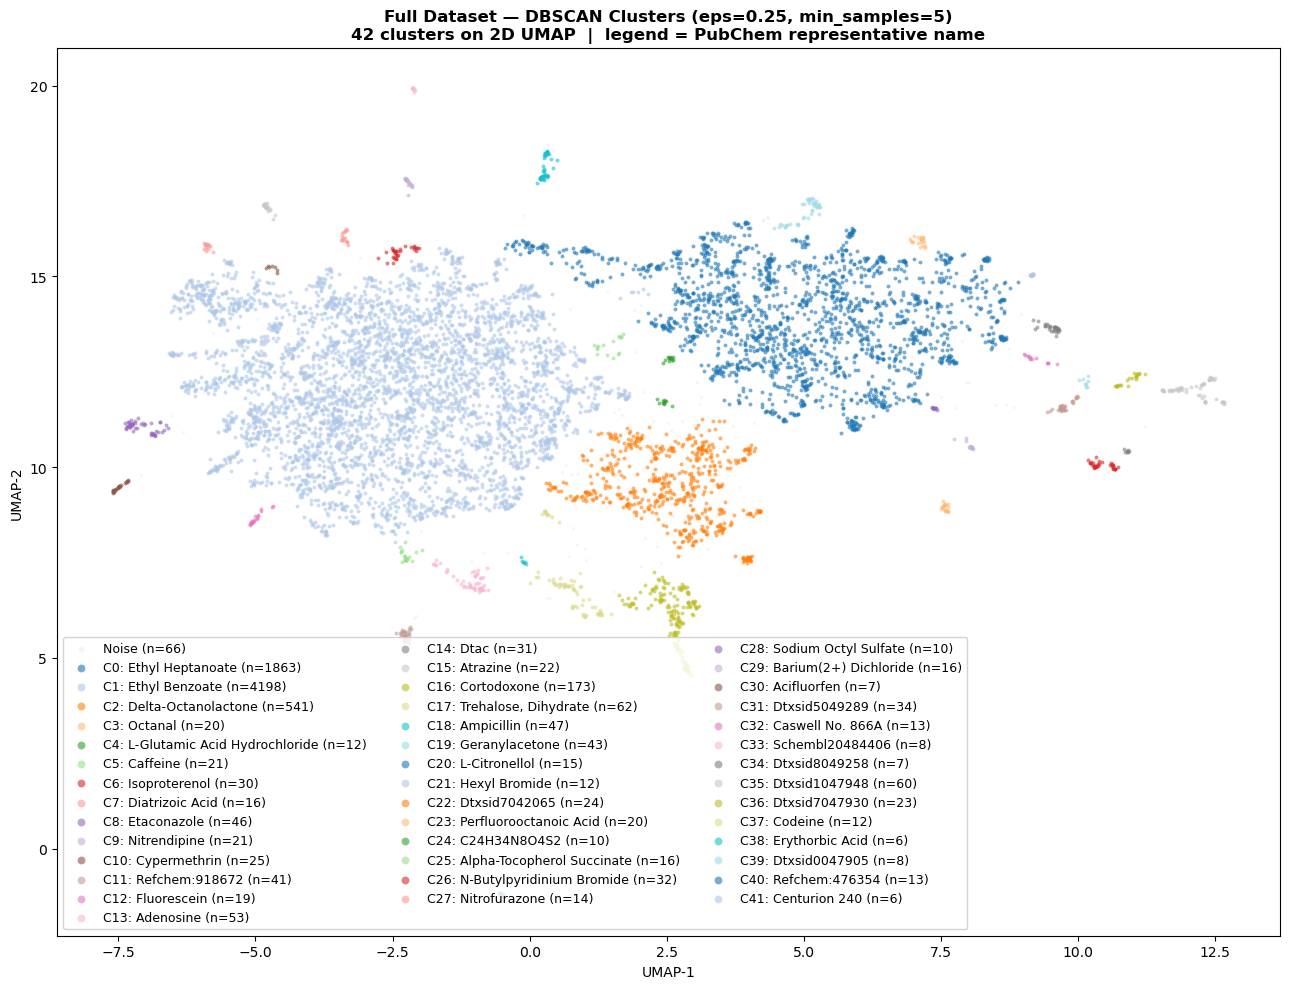

Saved → full_dataset_umap_by_cluster.png


In [28]:
# ── UMAP coloured by DBSCAN cluster, legend uses PubChem names ──────────────
cmap20 = plt.cm.tab20
cluster_ids = sorted(c for c in gvalid['cluster'].unique() if c != -1)

fig, ax = plt.subplots(figsize=(13, 10))
noise = gvalid[gvalid['cluster'] == -1]
ax.scatter(noise['umap_x'], noise['umap_y'],
           c='#e0e0e0', s=5, alpha=0.3, linewidths=0,
           label=f'Noise (n={len(noise)})', zorder=1)
for cl in cluster_ids:
    sub  = gvalid[gvalid['cluster'] == cl]
    name = cl_name_map.get(cl, f'C{cl}')
    ax.scatter(sub['umap_x'], sub['umap_y'],
               c=[cmap20(cl % 20)], s=8, alpha=0.6, linewidths=0,
               label=f'C{cl}: {name} (n={len(sub)})', zorder=2)
ax.set_title(f'Full Dataset — DBSCAN Clusters (eps={EPS}, min_samples={MIN_SAMPLES})\n'
             f'{n_cl} clusters on 2D UMAP  |  legend = PubChem representative name',
             fontsize=12, fontweight='bold')
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
ax.legend(fontsize=9, ncol=3, loc='lower left', framealpha=0.85, markerscale=2)
plt.tight_layout()
plt.savefig(RESULTS + 'full_dataset_umap_by_cluster.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved → full_dataset_umap_by_cluster.png')


---
## Section 3 — Cluster Composition: Active vs Inactive Enrichment

For each cluster, compute the fraction of compounds in each behavior category.
Clusters with high **active fraction** are structurally-defined families that preferentially activate caspase-3/7.

Top 20 clusters by active fraction (Active + Mixed-with-Active):
            n  Active  Mixed (with Active)  Inconclusive  Inactive  active_frac
cluster                                                                        
 32        13       1                    3             0         7     0.307692
 39         8       0                    2             0         6     0.250000
 22        24       0                    5             1        12     0.208333
 41         6       0                    1             0         5     0.166667
 17        62       3                    6             0        50     0.145161
 36        23       0                    3             0        19     0.130435
 3         20       0                    2             0        18     0.100000
 37        12       1                    0             0        11     0.083333
 8         46       0                    3             0        37     0.065217
 14        31       1                    1             

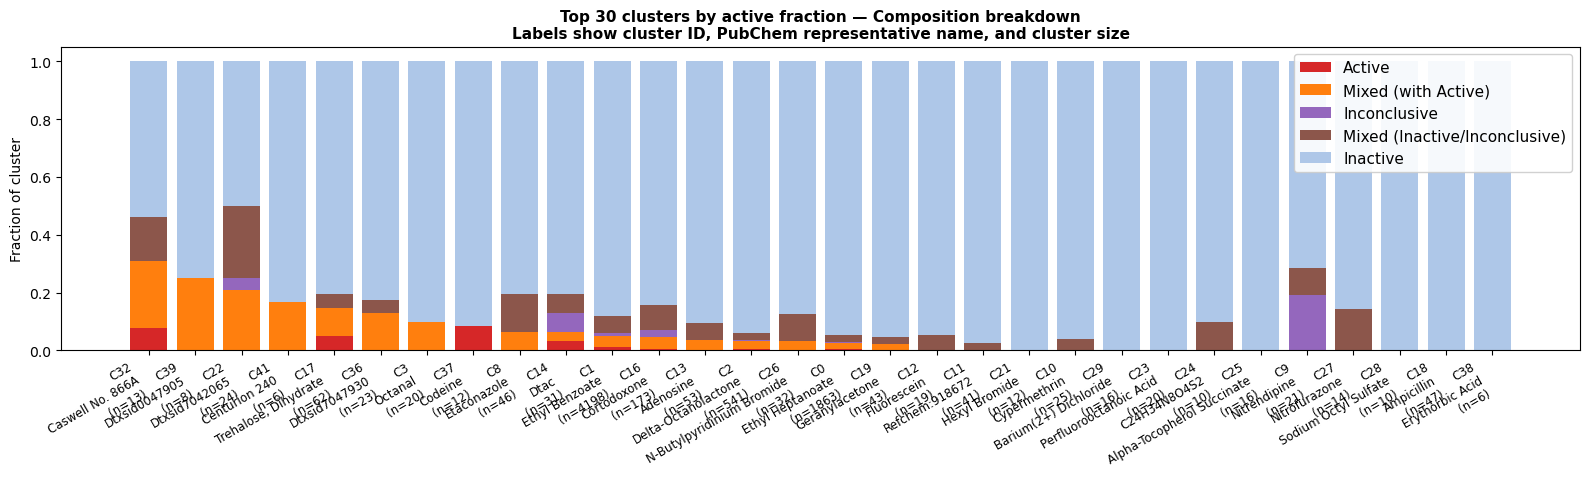

Saved → full_dataset_cluster_composition.png


In [29]:
cats_order = ['Active', 'Mixed (with Active)', 'Inconclusive',
              'Mixed (Inactive/Inconclusive)', 'Inactive']

rows = []
for cl in sorted(gvalid['cluster'].unique()):
    sub = gvalid[gvalid['cluster'] == cl]
    row = {'cluster': cl, 'n': len(sub)}
    for cat in cats_order:
        row[cat] = (sub['behavior_category'] == cat).sum()
    row['active_frac'] = (row['Active'] + row['Mixed (with Active)']) / len(sub)
    row['is_noise']    = cl == -1
    rows.append(row)

comp_df = pd.DataFrame(rows).set_index('cluster').sort_values('active_frac', ascending=False)

print('Top 20 clusters by active fraction (Active + Mixed-with-Active):')
print(comp_df[['n', 'Active', 'Mixed (with Active)', 'Inconclusive',
               'Inactive', 'active_frac']].head(20).to_string())

# ── Stacked bar chart (non-noise clusters with n >= 5) ────────────────────────
plot_df = comp_df[~comp_df['is_noise'] & (comp_df['n'] >= 5)].copy()
plot_df = plot_df.sort_values('active_frac', ascending=False).head(30)

fig, ax = plt.subplots(figsize=(16, 5))
bottom = np.zeros(len(plot_df))
x = np.arange(len(plot_df))
for cat in cats_order:
    vals = plot_df[cat].values / plot_df['n'].values
    ax.bar(x, vals, bottom=bottom, color=COLOR_MAP[cat], label=cat, width=0.8)
    bottom += vals
ax.set_xticks(x)
ax.set_xticklabels(
    [f'C{i}\n{cl_name_map.get(i, "")}\n(n={plot_df["n"].iloc[j]})'
     for j, i in enumerate(plot_df.index)],
    fontsize=8.5, rotation=30, ha='right'
)
ax.set_ylabel('Fraction of cluster')
ax.set_title('Top 30 clusters by active fraction — Composition breakdown\n'
             'Labels show cluster ID, PubChem representative name, and cluster size',
             fontsize=11, fontweight='bold')
ax.legend(loc='upper right', fontsize=11, framealpha=0.9)
plt.tight_layout()
plt.savefig(RESULTS + 'full_dataset_cluster_composition.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved → full_dataset_cluster_composition.png')


---
## Section 4 — Where Do the 323 Active Compounds Lie?

Overlay the 323 active compounds (Active + Mixed-with-Active) on the full UMAP.
Grey background = all 7K compounds.  
Coloured foreground = 323 active (red = pure Active, orange = Mixed-with-Active).

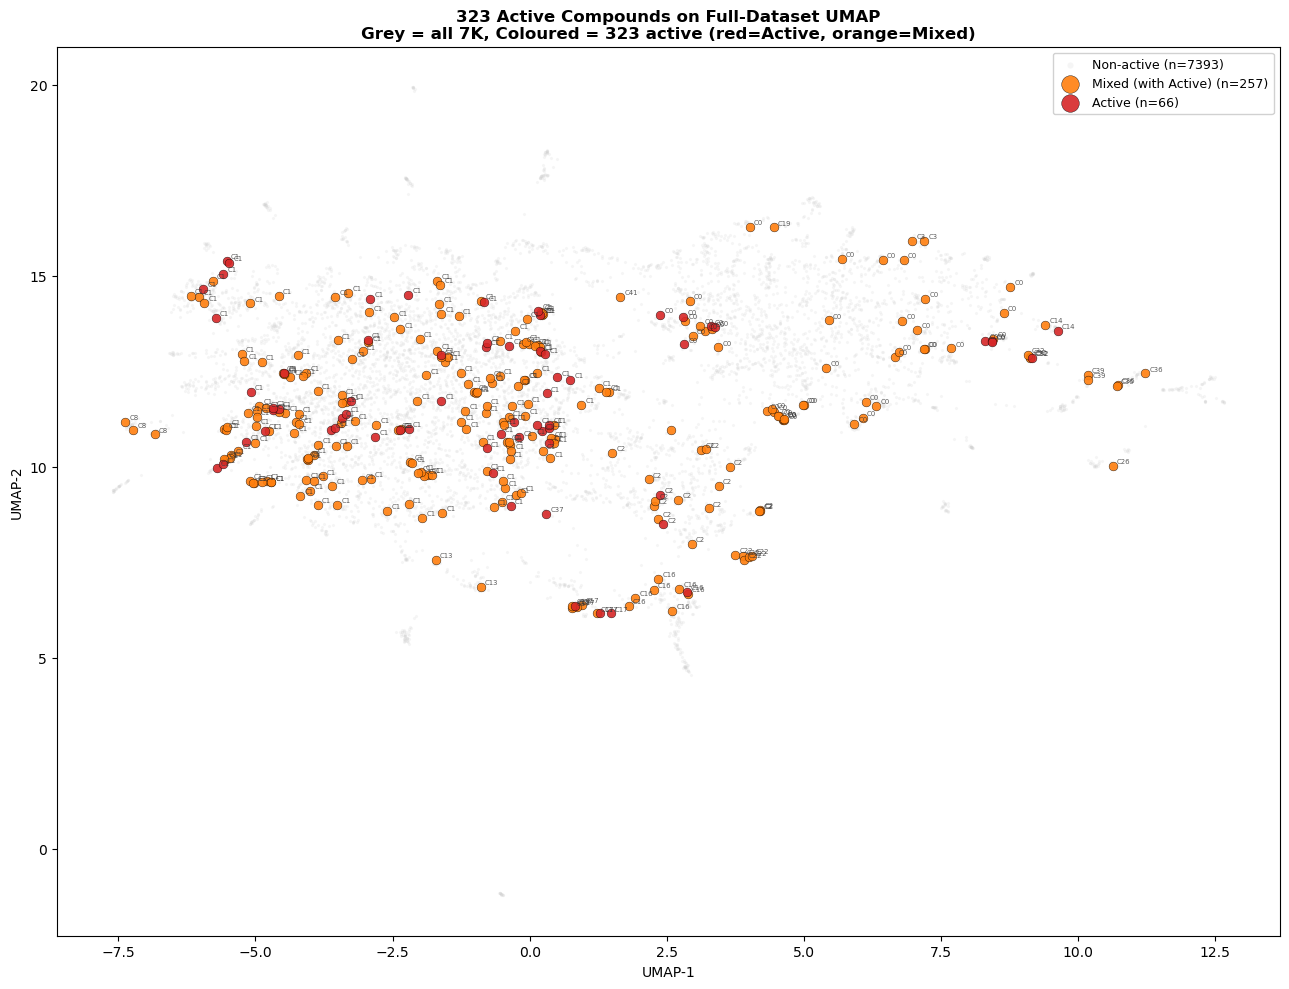

Saved → full_dataset_323_overlay.png

Clusters containing the 323 active compounds:
            n_active     n  active_frac
Cluster 1        214  4198     0.050977
Cluster 0         47  1863     0.025228
Cluster 2         17   541     0.031423
Cluster 17         9    62     0.145161
Cluster 16         8   173     0.046243
Cluster 22         5    24     0.208333
Cluster 32         4    13     0.307692
Cluster 36         3    23     0.130435
Cluster 8          3    46     0.065217
Cluster 3          2    20     0.100000
Cluster 13         2    53     0.037736
Cluster 14         2    31     0.064516
Cluster 39         2     8     0.250000
Cluster 37         1    12     0.083333
Noise              1    66     0.015152
Cluster 26         1    32     0.031250
Cluster 19         1    43     0.023256
Cluster 41         1     6     0.166667


In [30]:
mask_323  = gvalid['PUBCHEM_CID'].isin(cids_323)
mask_rest = ~mask_323

fig, ax = plt.subplots(figsize=(13, 10))

# Background — all non-active compounds
ax.scatter(
    gvalid.loc[mask_rest, 'umap_x'], gvalid.loc[mask_rest, 'umap_y'],
    c='#d0d0d0', s=5, alpha=0.2, linewidths=0, label=f'Non-active (n={mask_rest.sum()})', zorder=1
)

# Foreground — 323 active (color by sub-category)
for cat in ['Mixed (with Active)', 'Active']:
    m = mask_323 & (gvalid['behavior_category'] == cat)
    ax.scatter(
        gvalid.loc[m, 'umap_x'], gvalid.loc[m, 'umap_y'],
        c=COLOR_MAP[cat], s=40, alpha=0.9, linewidths=0.3,
        edgecolors='black', label=f'{cat} (n={m.sum()})', zorder=3
    )

# Annotate with cluster assignment
for _, row in gvalid[mask_323].iterrows():
    cl = row['cluster']
    if cl != -1:
        ax.annotate(f'C{cl}', (row['umap_x'], row['umap_y']),
                    textcoords='offset points', xytext=(3, 2),
                    fontsize=5, color='#333', alpha=0.8)

ax.set_title('323 Active Compounds on Full-Dataset UMAP\n'
             'Grey = all 7K, Coloured = 323 active (red=Active, orange=Mixed)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
ax.legend(fontsize=9, markerscale=2, framealpha=0.9)
plt.tight_layout()
plt.savefig(RESULTS + 'full_dataset_323_overlay.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved → full_dataset_323_overlay.png')

# ── Which clusters do the 323 active compounds fall into? ────────────────────
active323_clusters = (gvalid[mask_323]
                      .groupby('cluster').size()
                      .rename('n_active')
                      .to_frame()
                      .join(comp_df[['n', 'active_frac']])
                      .sort_values('n_active', ascending=False))
active323_clusters.index = ['Noise' if i == -1 else f'Cluster {i}'
                             for i in active323_clusters.index]
print('\nClusters containing the 323 active compounds:')
print(active323_clusters.head(20).to_string())

---
## Section 5 — Where Do the 104 Fully-Tested Active Compounds Lie?

These 104 compounds were tested in **all 14 cell lines** and active in at least one.
They are the most robustly characterised actives in the dataset.
Overlaid on top of the 323 (already shown in orange/red) with a distinct star marker.

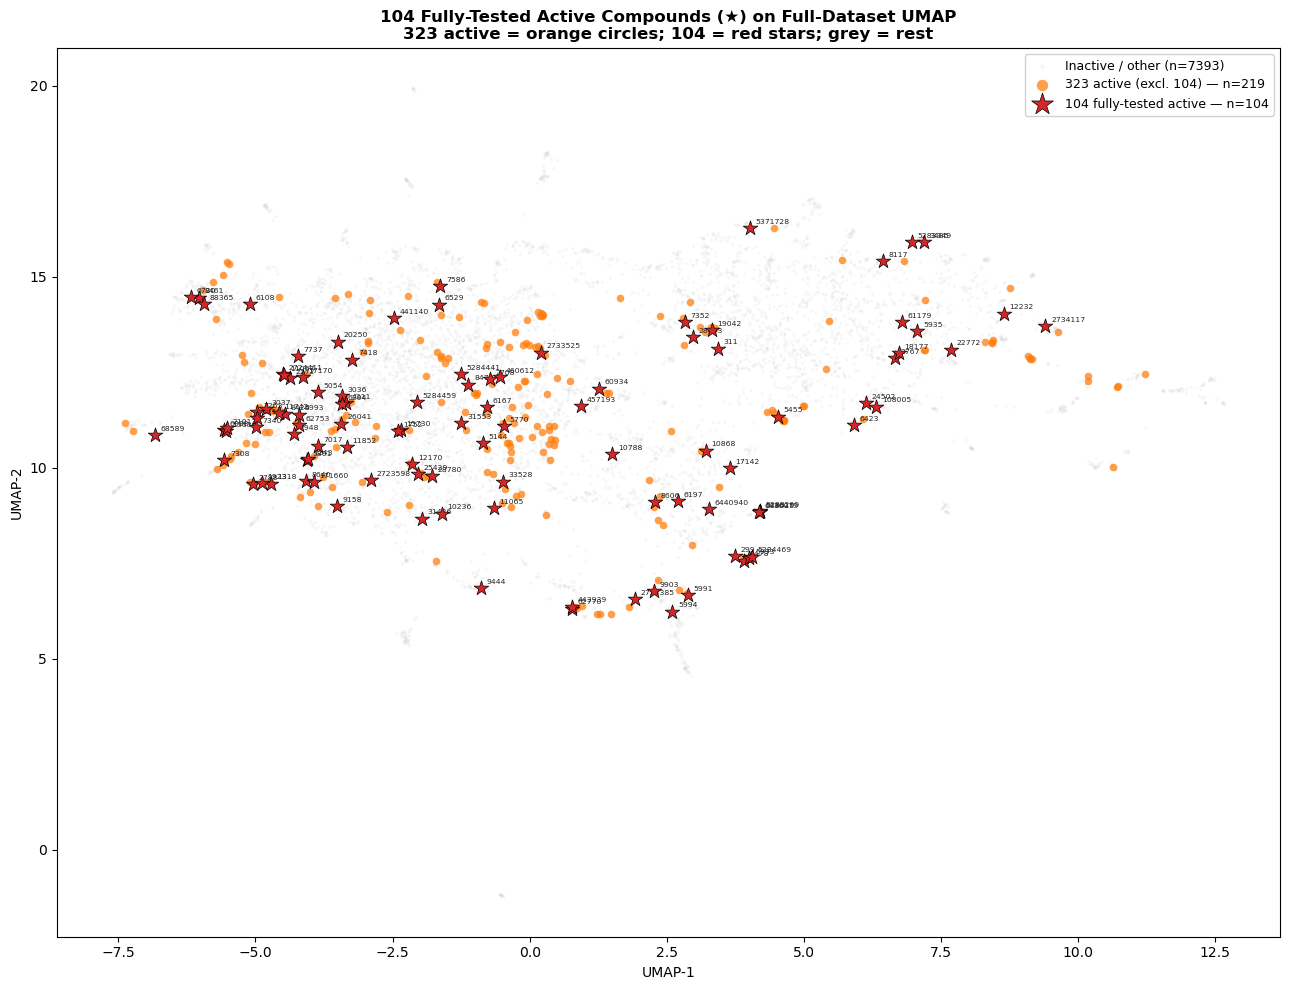

Saved → full_dataset_104_overlay.png

Clusters containing the 104 fully-tested active compounds:
            n_104     n  active_frac
Cluster 1      64  4198     0.050977
Cluster 0      16  1863     0.025228
Cluster 2       9   541     0.031423
Cluster 16      4   173     0.046243
Cluster 22      4    24     0.208333
Cluster 3       2    20     0.100000
Cluster 17      2    62     0.145161
Cluster 8       1    46     0.065217
Cluster 13      1    53     0.037736
Cluster 14      1    31     0.064516


In [31]:
mask_104   = gvalid['PUBCHEM_CID'].isin(cids_104)
mask_323_not_104 = mask_323 & ~mask_104

fig, ax = plt.subplots(figsize=(13, 10))

# Layer 1 — all inactive/other background
bg = gvalid[~mask_323]
ax.scatter(bg['umap_x'], bg['umap_y'],
           c='#d8d8d8', s=5, alpha=0.2, linewidths=0,
           label=f'Inactive / other (n={len(bg)})', zorder=1)

# Layer 2 — 323 minus the 104 (orange circles)
sub_323 = gvalid[mask_323_not_104]
ax.scatter(sub_323['umap_x'], sub_323['umap_y'],
           c='#ff7f0e', s=30, alpha=0.75, linewidths=0, marker='o',
           label=f'323 active (excl. 104) — n={len(sub_323)}', zorder=2)

# Layer 3 — 104 fully-tested actives (red stars)
sub_104 = gvalid[mask_104]
ax.scatter(sub_104['umap_x'], sub_104['umap_y'],
           c='#d62728', s=120, alpha=1.0, linewidths=0.5,
           edgecolors='black', marker='*',
           label=f'104 fully-tested active — n={len(sub_104)}', zorder=4)

# CID annotations for the 104
for _, row in sub_104.iterrows():
    ax.annotate(str(int(row['PUBCHEM_CID'])),
                (row['umap_x'], row['umap_y']),
                textcoords='offset points', xytext=(4, 3),
                fontsize=5.5, color='#222')

ax.set_title('104 Fully-Tested Active Compounds (★) on Full-Dataset UMAP\n'
             '323 active = orange circles; 104 = red stars; grey = rest',
             fontsize=12, fontweight='bold')
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
ax.legend(fontsize=9, markerscale=1.5, framealpha=0.9)
plt.tight_layout()
plt.savefig(RESULTS + 'full_dataset_104_overlay.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved → full_dataset_104_overlay.png')

# ── Which clusters do the 104 fall into? ─────────────────────────────────────
cl_104 = (gvalid[mask_104]
           .groupby('cluster').size()
           .rename('n_104')
           .to_frame()
           .join(comp_df[['n', 'active_frac']])
           .sort_values('n_104', ascending=False))
cl_104.index = ['Noise' if i == -1 else f'Cluster {i}' for i in cl_104.index]
print('\nClusters containing the 104 fully-tested active compounds:')
print(cl_104.to_string())

---
## Section 6 — Side-by-Side: 323 vs 104 vs All

Three-panel UMAP showing how the active sets nest within the full chemical space.

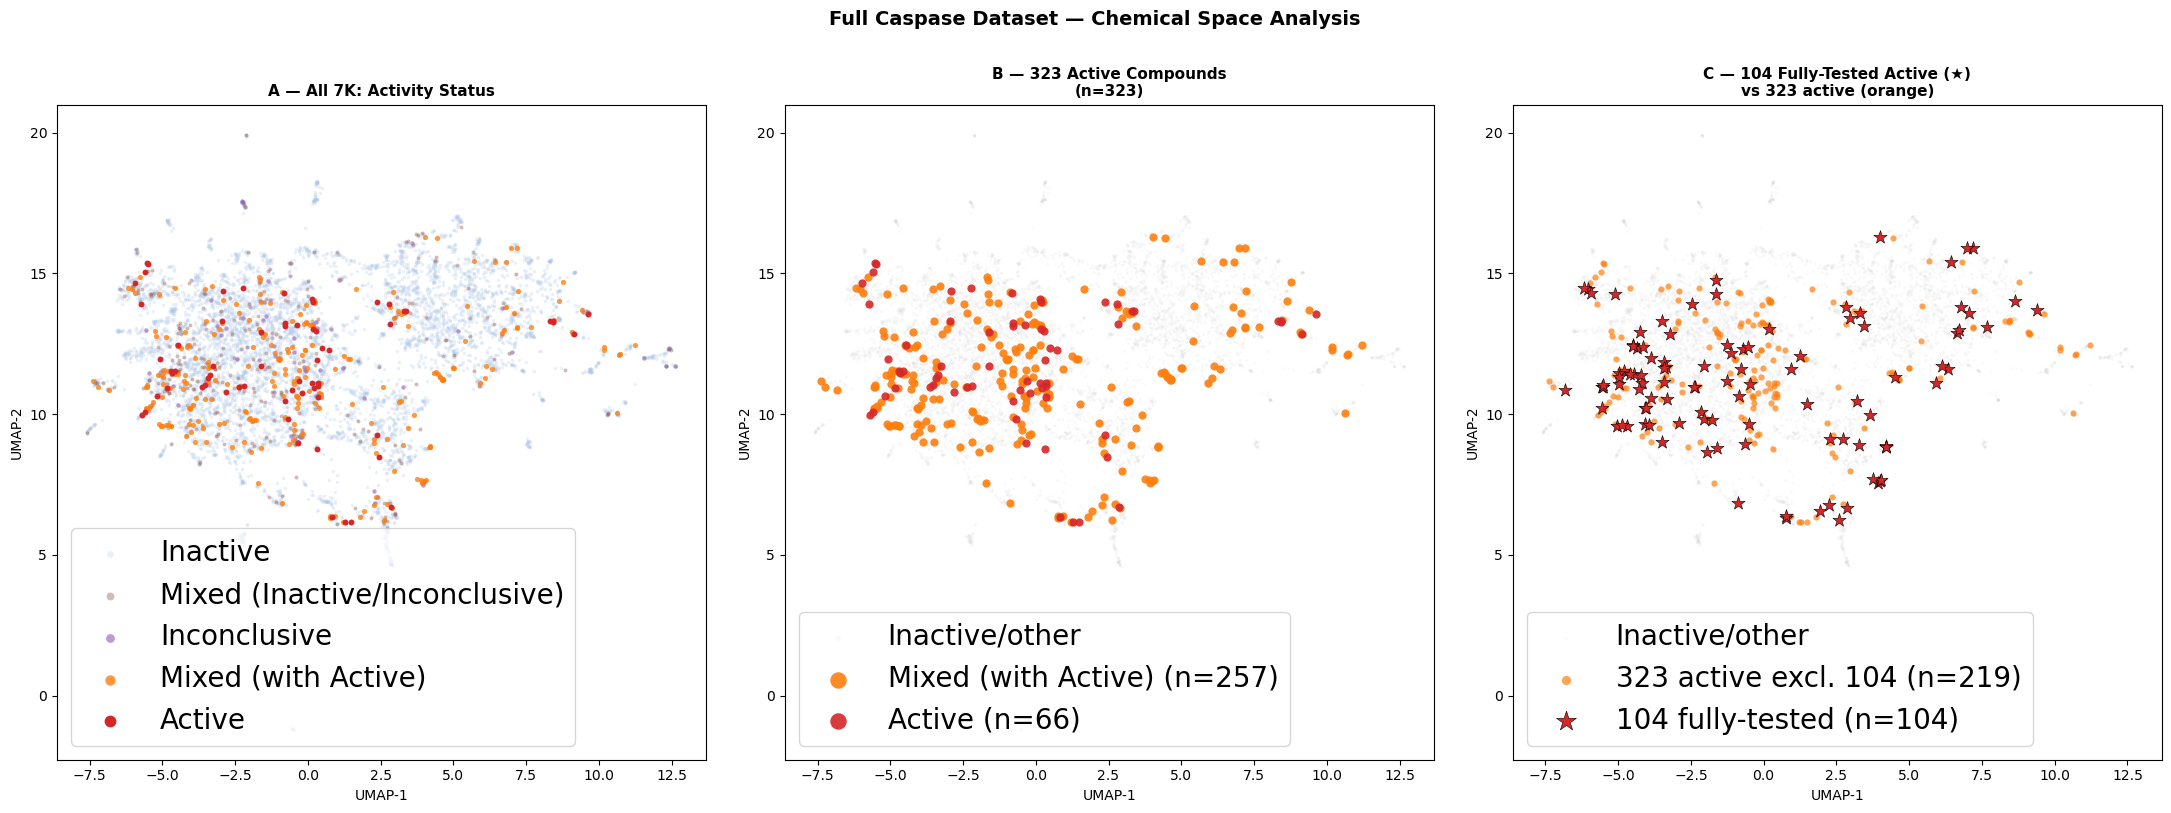

Saved → full_dataset_sidebyside.png


In [32]:
fig, axes = plt.subplots(1, 3, figsize=(22, 8))

# Panel A — Full dataset by behavior
ax = axes[0]
for cat in PLOT_ORDER:
    m = gvalid['behavior_category'] == cat
    ax.scatter(gvalid.loc[m, 'umap_x'], gvalid.loc[m, 'umap_y'],
               c=COLOR_MAP[cat], s=SIZES[cat], alpha=ALPHAS[cat],
               linewidths=0, label=cat, zorder=PLOT_ORDER.index(cat)+1)
ax.set_title('A — All 7K: Activity Status', fontsize=11, fontweight='bold')
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
ax.legend(fontsize=20, markerscale=2)

# Panel B — 323 active highlighted
ax = axes[1]
ax.scatter(gvalid.loc[~mask_323, 'umap_x'], gvalid.loc[~mask_323, 'umap_y'],
           c='#d8d8d8', s=4, alpha=0.15, linewidths=0, label='Inactive/other')
for cat in ['Mixed (with Active)', 'Active']:
    m = mask_323 & (gvalid['behavior_category'] == cat)
    ax.scatter(gvalid.loc[m, 'umap_x'], gvalid.loc[m, 'umap_y'],
               c=COLOR_MAP[cat], s=35, alpha=0.9, linewidths=0,
               label=f'{cat} (n={m.sum()})', zorder=3)
ax.set_title(f'B — 323 Active Compounds\n(n={len(cids_323)})', fontsize=11, fontweight='bold')
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
ax.legend(fontsize=20, markerscale=2)

# Panel C — 104 fully-tested active highlighted
ax = axes[2]
ax.scatter(gvalid.loc[~mask_323, 'umap_x'], gvalid.loc[~mask_323, 'umap_y'],
           c='#d8d8d8', s=4, alpha=0.15, linewidths=0, label='Inactive/other')
ax.scatter(gvalid.loc[mask_323_not_104, 'umap_x'],
           gvalid.loc[mask_323_not_104, 'umap_y'],
           c='#ff7f0e', s=20, alpha=0.7, linewidths=0,
           label=f'323 active excl. 104 (n={mask_323_not_104.sum()})', zorder=2)
ax.scatter(sub_104['umap_x'], sub_104['umap_y'],
           c='#d62728', s=100, alpha=1.0, marker='*',
           edgecolors='black', linewidths=0.4,
           label=f'104 fully-tested (n={len(sub_104)})', zorder=4)
ax.set_title(f'C — 104 Fully-Tested Active (★)\nvs 323 active (orange)',
             fontsize=11, fontweight='bold')
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
ax.legend(fontsize=20, markerscale=1.5)

plt.suptitle('Full Caspase Dataset — Chemical Space Analysis',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(RESULTS + 'full_dataset_sidebyside.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved → full_dataset_sidebyside.png')

---
## Section 7 — Active-Enriched Clusters: MCS Cores + Representatives

For every cluster where ≥20% of members are active (Active + Mixed-with-Active),
draw the MCS core scaffold and the 5 compounds nearest to the cluster centroid.
Common core atoms are highlighted in orange.

3 active-enriched clusters (active_frac >= 20%, n >= 5):
          n  Active  Mixed (with Active)  active_frac
cluster                                              
32       13       1                    3     0.307692
39        8       0                    2     0.250000
22       24       0                    5     0.208333

── Cluster 32: Caswell No. 866A  (n=13, Active=1, Mixed=3, frac=30.8%) ──


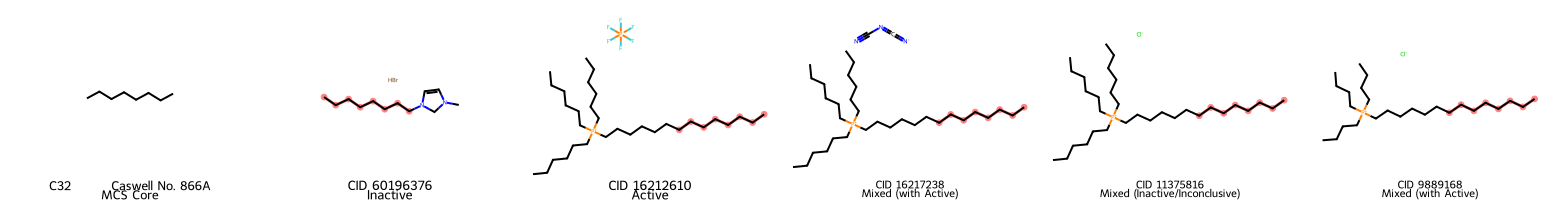


── Cluster 39: Dtxsid0047905  (n=8, Active=0, Mixed=2, frac=25.0%) ──


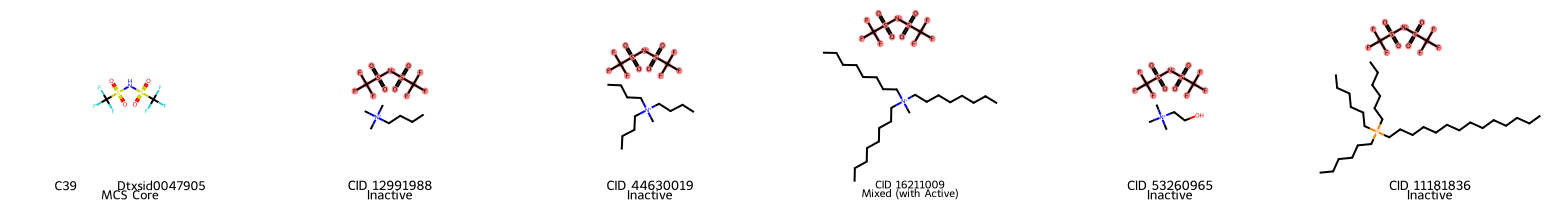


── Cluster 22: Dtxsid7042065  (n=24, Active=0, Mixed=5, frac=20.8%) ──


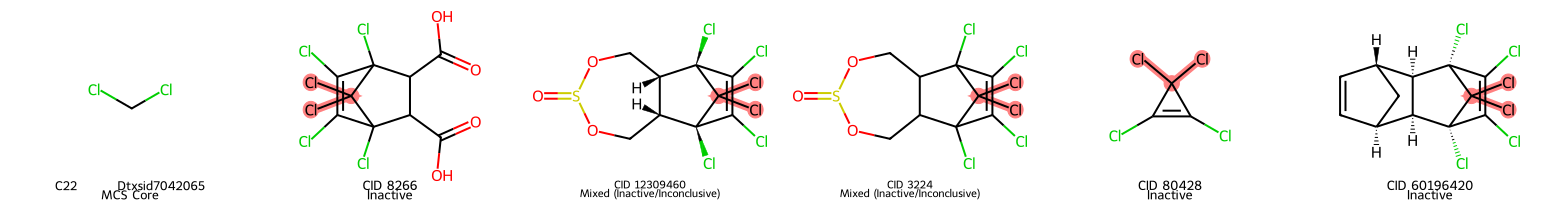

In [33]:
from IPython.display import display

# Clusters with active_frac >= 0.20 AND n >= 5 AND not noise
ACTIVE_FRAC_THRESHOLD = 0.20
ae_clusters = comp_df[
    (~comp_df['is_noise']) &
    (comp_df['n'] >= 5) &
    (comp_df['active_frac'] >= ACTIVE_FRAC_THRESHOLD)
].index.tolist()

print(f'{len(ae_clusters)} active-enriched clusters '
      f'(active_frac >= {ACTIVE_FRAC_THRESHOLD:.0%}, n >= 5):')
print(comp_df.loc[ae_clusters, ['n', 'Active', 'Mixed (with Active)', 'active_frac']]
      .sort_values('active_frac', ascending=False).to_string())

for cl in sorted(ae_clusters, key=lambda c: -comp_df.loc[c, 'active_frac']):
    sub   = gvalid[gvalid['cluster'] == cl].copy()
    n_act = comp_df.loc[cl, 'Active']
    n_mix = comp_df.loc[cl, 'Mixed (with Active)']
    n_tot = comp_df.loc[cl, 'n']
    frac  = comp_df.loc[cl, 'active_frac']
    name  = cl_name_map.get(cl, f'C{cl}')

    print(f'\n── Cluster {cl}: {name}  '
          f'(n={n_tot}, Active={n_act}, Mixed={n_mix}, frac={frac:.1%}) ──')

    reps = pick_central(sub, n_max=5)
    mols = [m for m in reps['mol'].tolist() if m is not None]
    core = get_mcs_core(mols)

    draw_mols, draw_legs, draw_hi = [], [], []
    if core is not None:
        draw_mols.append(core)
        draw_legs.append(f'C{cl} — {name}\nMCS Core')
        draw_hi.append([])
    for _, row in reps.iterrows():
        if row['mol'] is None:
            continue
        cid = int(row['PUBCHEM_CID'])
        cat = row['behavior_category']
        draw_mols.append(row['mol'])
        draw_legs.append(f'CID {cid}\n{cat}')
        if core is not None:
            try:
                draw_hi.append(list(row['mol'].GetSubstructMatch(core)))
            except Exception:
                draw_hi.append([])
        else:
            draw_hi.append([])

    if draw_mols:
        img = Draw.MolsToGridImage(
            draw_mols, molsPerRow=min(6, len(draw_mols)),
            subImgSize=(260, 210),
            legends=draw_legs,
            highlightAtomLists=draw_hi,
            returnPNG=False
        )
        display(img)


---
## Section 8 — Are 104 and 323 in the Same Clusters? Proximity Analysis

Check how many of the 104 fully-tested actives share a cluster with other active compounds,
and how close (in UMAP space) they are to the 323 active set.

104 fully-tested active compounds that are also in the 323: 104
104 NOT in 323 (mixed with inactive at fully-tested level): 0

104 cluster assignments (with PubChem names):
  C1: Ethyl Benzoate  →  64 compounds
  C0: Ethyl Heptanoate  →  16 compounds
  C2: Delta-Octanolactone  →  9 compounds
  C16: Cortodoxone  →  4 compounds
  C22: Dtxsid7042065  →  4 compounds
  C17: Trehalose, Dihydrate  →  2 compounds
  C3: Octanal  →  2 compounds
  C13: Adenosine  →  1 compounds
  C8: Etaconazole  →  1 compounds
  C14: Dtac  →  1 compounds

323 cluster assignments (with PubChem names):
  C1: Ethyl Benzoate  →  214 compounds
  C0: Ethyl Heptanoate  →  47 compounds
  C2: Delta-Octanolactone  →  17 compounds
  C17: Trehalose, Dihydrate  →  9 compounds
  C16: Cortodoxone  →  8 compounds
  C22: Dtxsid7042065  →  5 compounds
  C32: Caswell No. 866A  →  4 compounds
  C36: Dtxsid7047930  →  3 compounds
  C8: Etaconazole  →  3 compounds
  C39: Dtxsid0047905  →  2 compounds
  C13: Adenosine  →  2 compounds


[07:49:41] Explicit valence for atom # 8 N, 4, is greater than permitted
[07:49:41] Can't kekulize mol.  Unkekulized atoms: 11 12 14
[07:49:41] Explicit valence for atom # 8 N, 4, is greater than permitted


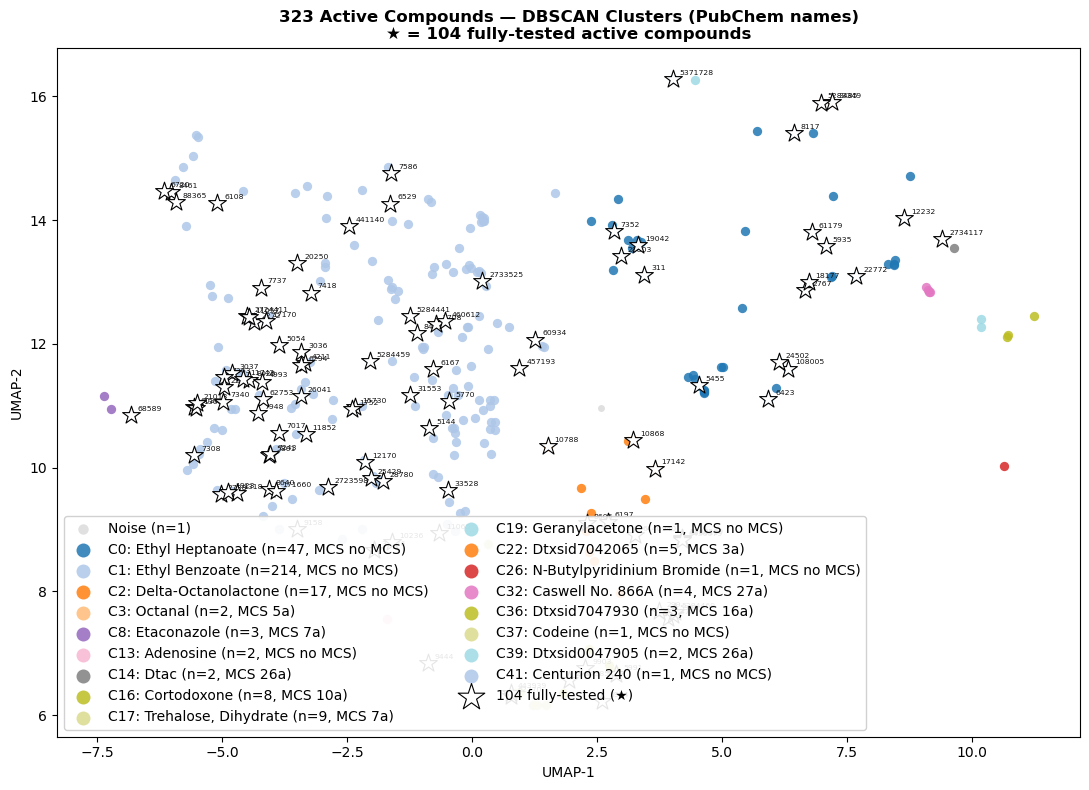

Saved → full_dataset_323_104_clusters.png


In [34]:
# ── Overlap: how many of the 104 are also in the 323? ─────────────────────────
overlap = cids_104 & cids_323
print(f'104 fully-tested active compounds that are also in the 323: {len(overlap)}')
print(f'104 NOT in 323 (mixed with inactive at fully-tested level): {len(cids_104 - cids_323)}')

# ── Cluster membership comparison ────────────────────────────────────────────
g104 = gvalid[gvalid['PUBCHEM_CID'].isin(cids_104)].copy()
g323 = gvalid[gvalid['PUBCHEM_CID'].isin(cids_323)].copy()

print(f'\n104 cluster assignments (with PubChem names):')
for cl, cnt in g104['cluster'].value_counts().items():
    label = 'Noise' if cl == -1 else f'C{cl}: {cl_name_map.get(cl, str(cl))}'
    print(f'  {label}  →  {cnt} compounds')

print(f'\n323 cluster assignments (with PubChem names):')
for cl, cnt in g323['cluster'].value_counts().items():
    label = 'Noise' if cl == -1 else f'C{cl}: {cl_name_map.get(cl, str(cl))}'
    print(f'  {label}  →  {cnt} compounds')

# ── Focused UMAP: 323 active, coloured by cluster, names + MCS in legend ────
# Precompute MCS SMARTS atom count for each cluster in 323
mcs_info_323 = {}
for cl in sorted(c for c in g323['cluster'].unique() if c != -1):
    sub_mols = [m for m in g323[g323['cluster'] == cl]['mol'].tolist() if m is not None]
    core = get_mcs_core(sub_mols)
    if core is not None:
        smi = Chem.MolToSmiles(core)
        n_atoms = core.GetNumAtoms()
        mcs_info_323[cl] = f'{n_atoms}a'  # short: "16a" = 16-atom common core
    else:
        mcs_info_323[cl] = 'no MCS'

cmap20 = plt.cm.tab20
fig, ax = plt.subplots(figsize=(11, 8))

noise_323 = g323[g323['cluster'] == -1]
ax.scatter(noise_323['umap_x'], noise_323['umap_y'],
           c='#cccccc', s=25, alpha=0.6, linewidths=0,
           label=f'Noise (n={len(noise_323)})', zorder=1)

cl_ids = sorted(c for c in g323['cluster'].unique() if c != -1)
for cl in cl_ids:
    sub  = g323[g323['cluster'] == cl]
    name = cl_name_map.get(cl, f'C{cl}')
    mcs_tag = mcs_info_323.get(cl, '')
    ax.scatter(sub['umap_x'], sub['umap_y'],
               c=[cmap20(cl % 20)], s=45, alpha=0.85, linewidths=0,
               label=f'C{cl}: {name} (n={len(sub)}, MCS {mcs_tag})', zorder=2)

# Star overlay for the 104
ax.scatter(g104['umap_x'], g104['umap_y'],
           c='white', s=180, alpha=1.0, marker='*',
           edgecolors='black', linewidths=0.8,
           label=f'104 fully-tested (\u2605)', zorder=5)

for _, row in g104.iterrows():
    ax.annotate(str(int(row['PUBCHEM_CID'])),
                (row['umap_x'], row['umap_y']),
                textcoords='offset points', xytext=(5, 3),
                fontsize=5.5, color='#111')

ax.set_title('323 Active Compounds — DBSCAN Clusters (PubChem names)\n'
             '\u2605 = 104 fully-tested active compounds',
             fontsize=12, fontweight='bold')
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
ax.legend(fontsize=10, ncol=2, framealpha=0.9, markerscale=1.5)
plt.tight_layout()
plt.savefig(RESULTS + 'full_dataset_323_104_clusters.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved → full_dataset_323_104_clusters.png')


---
## Section 9 — Multi-Cell-Line Activity Analysis

Two views:
1. **UMAP coloured by active-cell-line count** — highlights promiscuous activators (active in many cell lines)
2. **Per-cell-line bar chart** — how many compounds are active in each of the 14 cell lines


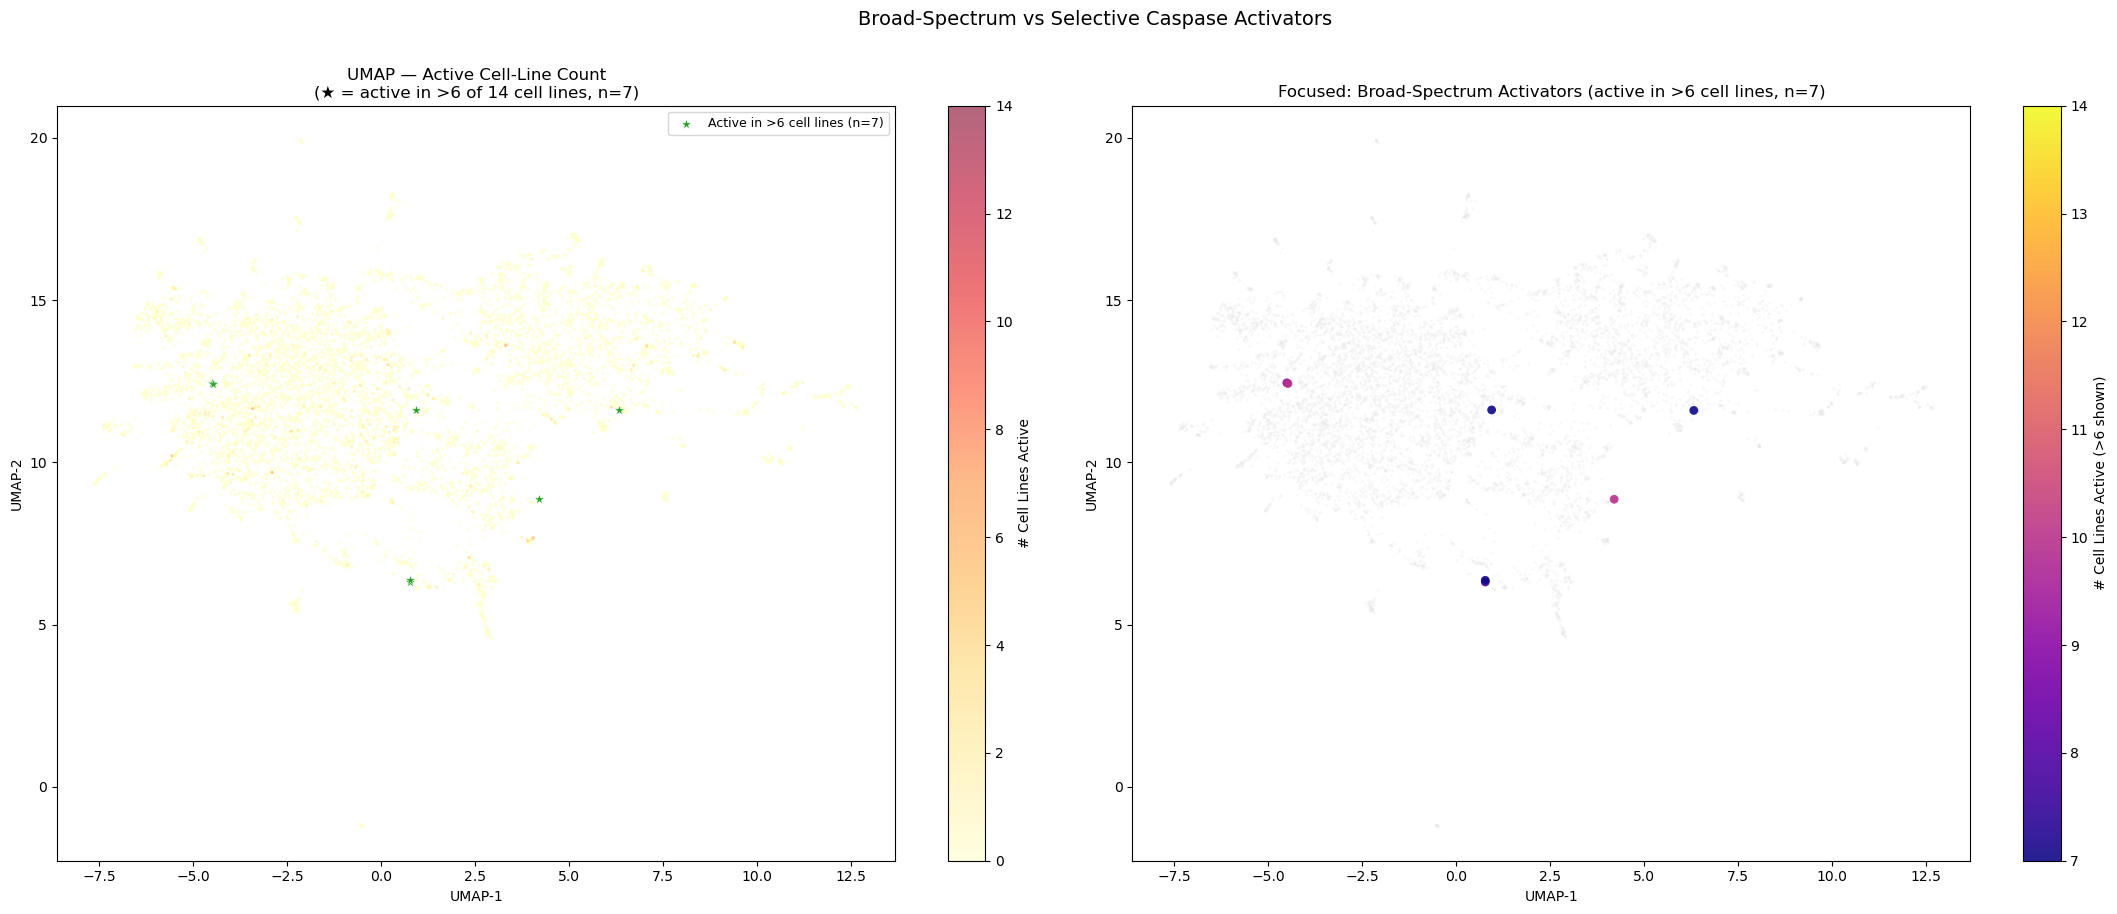

Saved: umap_active_cellline_count.png


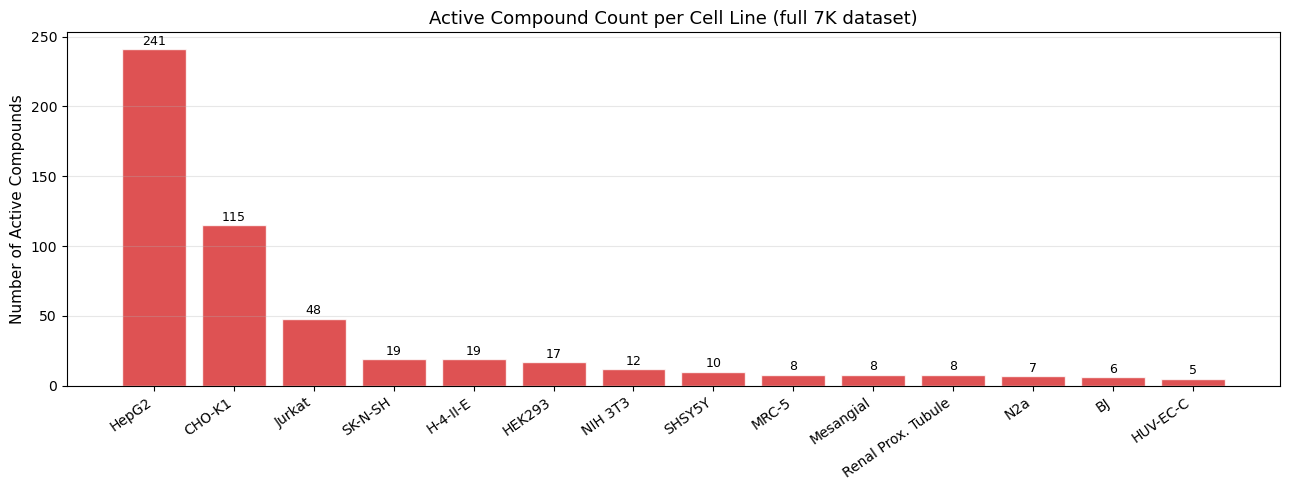


Active counts per cell line:
HepG2                 241
CHO-K1                115
Jurkat                 48
SK-N-SH                19
H-4-II-E               19
HEK293                 17
NIH 3T3                12
SHSY5Y                 10
MRC-5                   8
Mesangial               8
Renal Prox. Tubule      8
N2a                     7
BJ                      6
HUV-EC-C                5

Compounds active in >6 cell lines (n=7):
 PUBCHEM_CID  n_active_celllines                                 behavior
       11057                  10            Mixed (Active + Inconclusive)
     5288209                  10 Mixed (Active + Inactive + Inconclusive)
     2724411                   9 Mixed (Active + Inactive + Inconclusive)
       62770                   8 Mixed (Active + Inactive + Inconclusive)
      457193                   7 Mixed (Active + Inactive + Inconclusive)
      108005                   7 Mixed (Active + Inactive + Inconclusive)
      443939                   7 Mixed (Active

In [35]:
# ── Cell line name mapping ────────────────────────────────────────────────────
CELLLINE_NAMES = {
    'AID_1346980':                'CHO-K1',
    'AID_655':                    'Jurkat',
    'AID_656':                    'HUV-EC-C',
    'AID_657':                    'SHSY5Y',
    'AID_658':                    'BJ',
    'AID_659':                    'MRC-5',
    'AID_660':                    'Mesangial',
    'AID_661':                    'SK-N-SH',
    'AID_663':                    'H-4-II-E',
    'AID_664':                    'HEK293',
    'AID_665':                    'N2a',
    'AID_666':                    'NIH 3T3',
    'AID_667':                    'Renal Prox. Tubule',
    'combined_hepg2_casepase.csv':'HepG2',
}

# Add n_active_celllines to gvalid (join from gall)
if 'n_active_celllines' not in gvalid.columns:
    gvalid = gvalid.merge(
        gall[['PUBCHEM_CID', 'n_active_celllines']],
        on='PUBCHEM_CID', how='left')

# ── Plot 1: UMAP coloured by active-cell-line count ───────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(22, 9))

# Left panel: full dataset coloured by n_active_celllines
ax = axes[0]
sc = ax.scatter(
    gvalid['umap_x'], gvalid['umap_y'],
    c=gvalid['n_active_celllines'],
    cmap='YlOrRd', s=5, alpha=0.6, linewidths=0,
    vmin=0, vmax=14)
cb = plt.colorbar(sc, ax=ax, label='# Cell Lines Active')
cb.set_ticks(range(0, 15, 2))

# Overlay >6 as stars
g_gt6 = gvalid[gvalid['PUBCHEM_CID'].isin(cids_gt6)]
ax.scatter(g_gt6['umap_x'], g_gt6['umap_y'],
           c='#2ca02c', s=60, marker='*', linewidths=0.4,
           edgecolors='white', zorder=5,
           label=f'Active in >6 cell lines (n={len(g_gt6)})')
ax.legend(fontsize=9, loc='upper right')
ax.set_title(f'UMAP — Active Cell-Line Count\n(★ = active in >6 of 14 cell lines, n={len(g_gt6)})',
             fontsize=12)
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')

# Right panel: focused on >6 actives only, coloured by exact count
ax2 = axes[1]
# grey background — all compounds
ax2.scatter(gvalid['umap_x'], gvalid['umap_y'],
            c='#e8e8e8', s=4, alpha=0.3, linewidths=0, zorder=1)
# Colour >6 by count
counts = g_gt6['n_active_celllines'].values
cmap_gt6 = plt.cm.plasma
norm_gt6 = plt.Normalize(vmin=7, vmax=14)
sc2 = ax2.scatter(g_gt6['umap_x'], g_gt6['umap_y'],
                  c=counts, cmap=cmap_gt6, norm=norm_gt6,
                  s=40, alpha=0.9, linewidths=0, zorder=3)
cb2 = plt.colorbar(sc2, ax=ax2, label='# Cell Lines Active (>6 shown)')
cb2.set_ticks(range(7, 15))
ax2.set_title(f'Focused: Broad-Spectrum Activators (active in >6 cell lines, n={len(g_gt6)})',
              fontsize=12)
ax2.set_xlabel('UMAP-1'); ax2.set_ylabel('UMAP-2')

plt.suptitle('Broad-Spectrum vs Selective Caspase Activators', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(RESULTS + 'umap_active_cellline_count.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: umap_active_cellline_count.png')

# ── Plot 2: Per-cell-line active compound count (bar chart) ──────────────────
# Merge assay columns back to gvalid (they may have been dropped earlier)
assay_data = gall[['PUBCHEM_CID'] + ASSAY_COLS].copy()
gv_assay   = gvalid[['PUBCHEM_CID', 'behavior_category']].merge(
    assay_data, on='PUBCHEM_CID', how='left')

cl_counts = {}
for col in ASSAY_COLS:
    cl_name = CELLLINE_NAMES.get(col, col)
    cl_counts[cl_name] = (gv_assay[col] == 'Active').sum()

cl_df = pd.Series(cl_counts).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(range(len(cl_df)), cl_df.values, color='#d62728', alpha=0.8, edgecolor='white')
ax.set_xticks(range(len(cl_df)))
ax.set_xticklabels(cl_df.index, rotation=35, ha='right', fontsize=10)
ax.set_ylabel('Number of Active Compounds', fontsize=11)
ax.set_title('Active Compound Count per Cell Line (full 7K dataset)', fontsize=13)
for bar, val in zip(bars, cl_df.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            str(val), ha='center', va='bottom', fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS + 'active_counts_per_cellline.png', dpi=150, bbox_inches='tight')
plt.show()
print('\nActive counts per cell line:')
print(cl_df.to_string())

# ── Summary table: >6 active cell lines ──────────────────────────────────────
g_gt6_info = gall[gall['PUBCHEM_CID'].isin(cids_gt6)][['PUBCHEM_CID', 'n_active_celllines', 'behavior']].copy()
g_gt6_info = g_gt6_info.sort_values('n_active_celllines', ascending=False)
print(f'\nCompounds active in >6 cell lines (n={len(g_gt6_info)}):')
print(g_gt6_info.to_string(index=False))


---
## Section 10 — UMAP Grid: One Panel per Cell Line

14 mini-UMAPs, one per cell line. Grey background = all compounds with valid mols.
Red/orange points = compounds **Active** in that specific cell line.
Lets you see which chemical regions of UMAP space are recruited by each cell line.


Precomputing MCS cores for all clusters (this may take ~1-2 min)...


[07:49:42] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 7
[07:49:42] Explicit valence for atom # 14 N, 4, is greater than permitted
[07:49:42] Can't kekulize mol.  Unkekulized atoms: 0 1 2 3 4
[07:49:42] Can't kekulize mol.  Unkekulized atoms: 2 3 5
[07:49:42] Can't kekulize mol.  Unkekulized atoms: 3 4 6


  MCS found for 29 / 42 clusters

=== Cluster Name Verification: PubChem representative name vs MCS SMILES ===
 Cluster  PubChem Rep Name                        MCS SMILES
──────────────────────────────────────────────────────────────────────────────────────────────────────────────
C     0  Ethyl Heptanoate                        —
C     1  Ethyl Benzoate                          —
C     2  Delta-Octanolactone                     —
C     3  Octanal                                 CCC
C     4  L-Glutamic Acid Hydrochloride           CC(N)C(=O)O
C     5  Caffeine                                —
C     6  Isoproterenol                           CCc1ccccc1
C     7  Diatrizoic Acid                         CC(=O)Nc1c(I)cc(I)c(C=O)c1I
C     8  Etaconazole                             c1ccccc1
C     9  Nitrendipine                            c1ccccc1
C    10  Cypermethrin                            O=CO
C    11  Refchem:918672                          —
C    12  Fluorescein                     

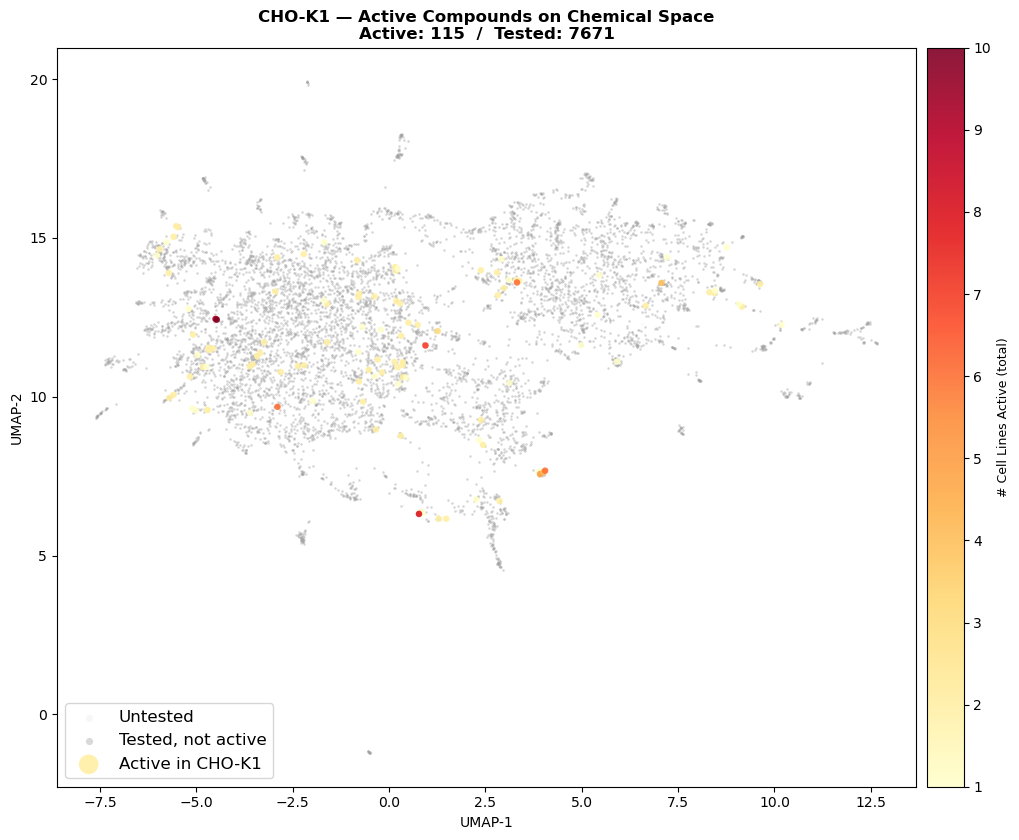

Saved: umap_cellline_AID_1346980.png

  Active-enriched clusters in CHO-K1 (active_frac >= 20%, n >= 5):
     C#  PubChem Name                         MCS SMILES                                          act_here  total_act_frac
  ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  C  22  Dtxsid7042065                        ClCCl                                                      4  20.8%
  C  32  Caswell No. 866A                     —                                                          2  30.8%
  C  39  Dtxsid0047905                        O=[SH](=O)C(F)(F)F                                         1  25.0%

  C22 (Dtxsid7042065) — MCS core + active reps in CHO-K1:


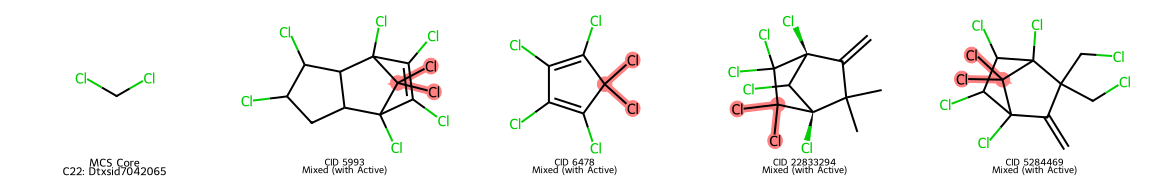


  C32 (Caswell No. 866A) — MCS core + active reps in CHO-K1:


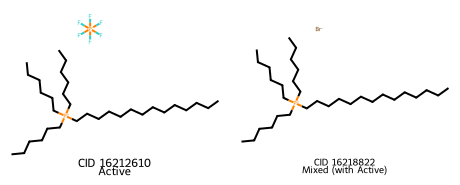


  C39 (Dtxsid0047905) — MCS core + active reps in CHO-K1:


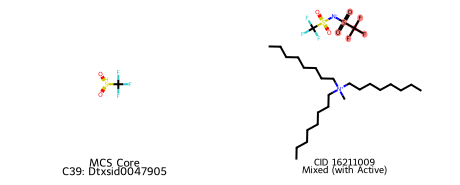

══════════════════════════════════════════════════════════════════════


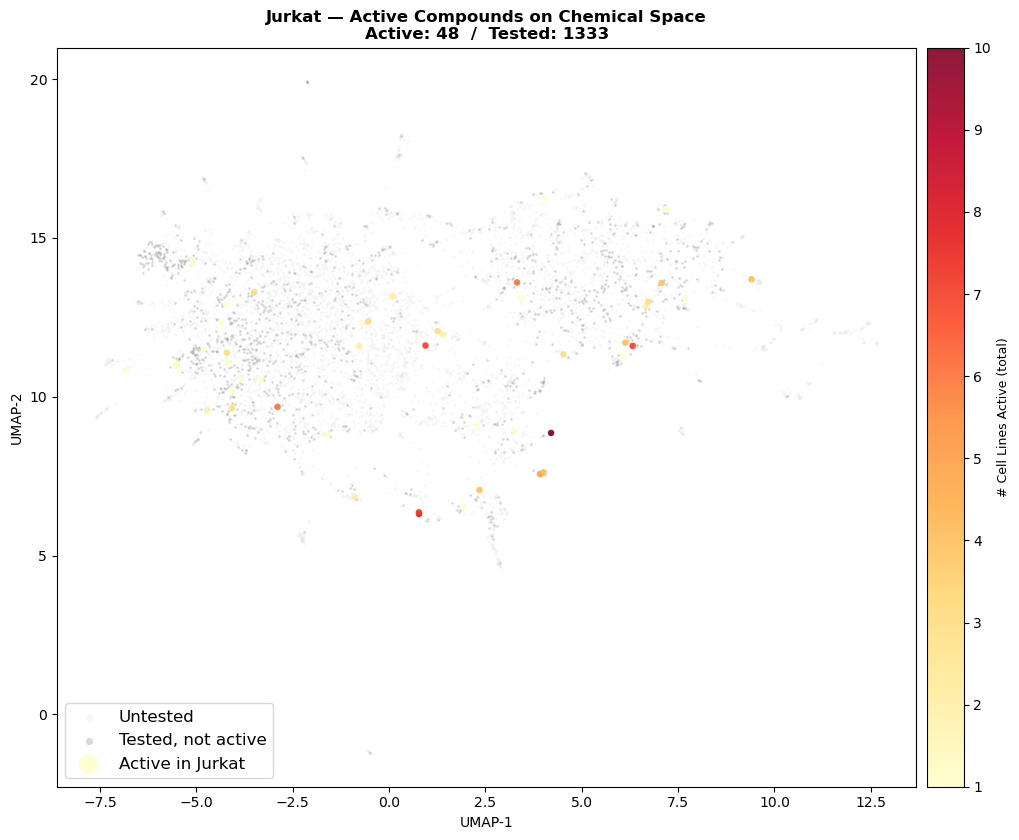

Saved: umap_cellline_AID_655.png

  Active-enriched clusters in Jurkat (active_frac >= 20%, n >= 5):
     C#  PubChem Name                         MCS SMILES                                          act_here  total_act_frac
  ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  C  22  Dtxsid7042065                        ClCCl                                                      2  20.8%

  C22 (Dtxsid7042065) — MCS core + active reps in Jurkat:


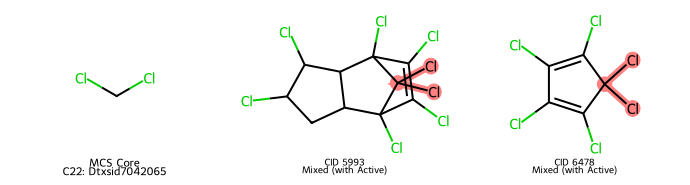

══════════════════════════════════════════════════════════════════════


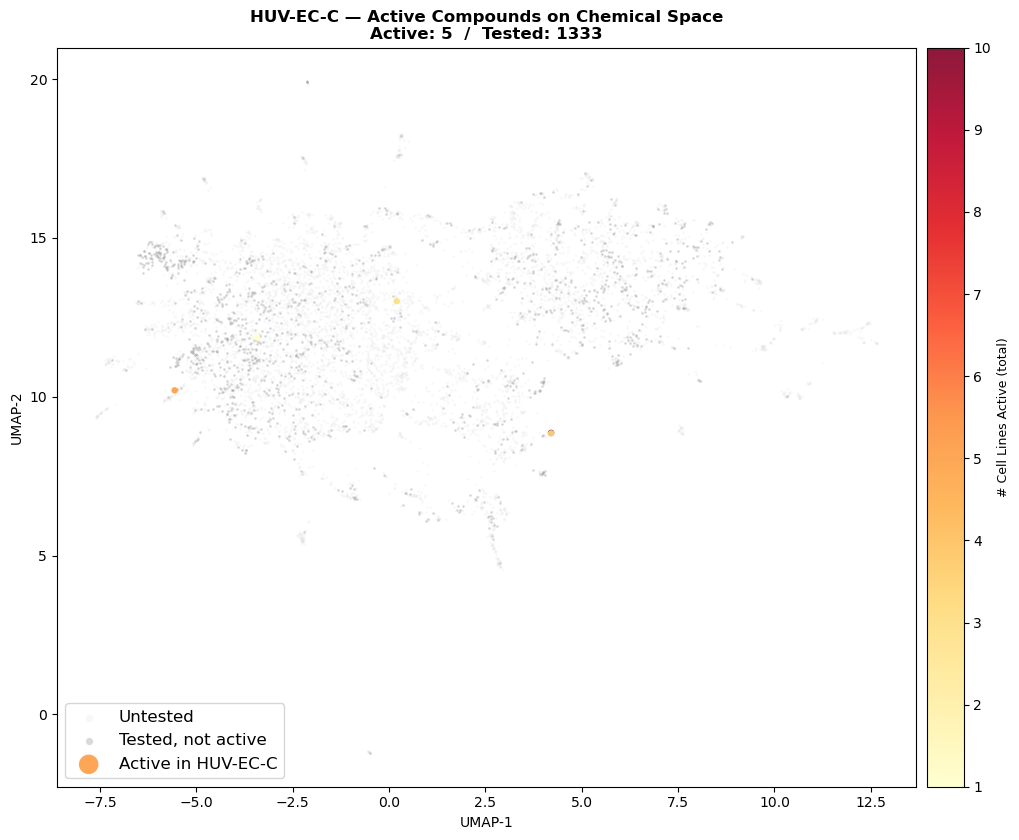

Saved: umap_cellline_AID_656.png
══════════════════════════════════════════════════════════════════════


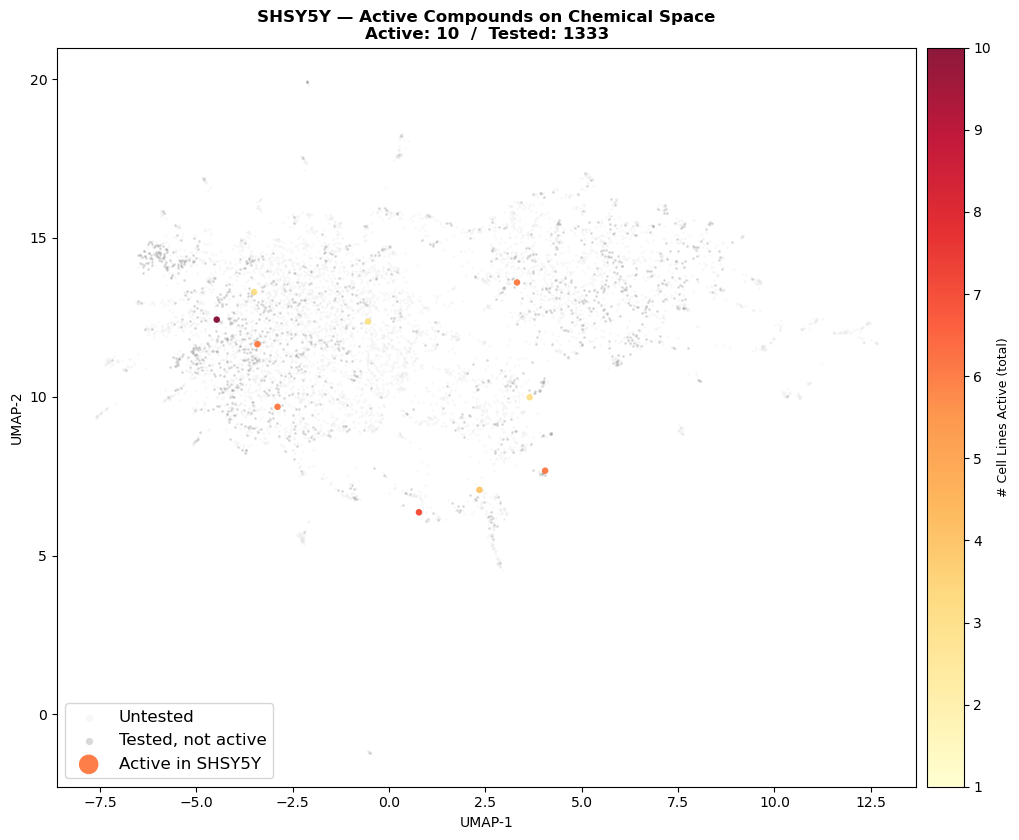

Saved: umap_cellline_AID_657.png

  Active-enriched clusters in SHSY5Y (active_frac >= 20%, n >= 5):
     C#  PubChem Name                         MCS SMILES                                          act_here  total_act_frac
  ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  C  22  Dtxsid7042065                        ClCCl                                                      1  20.8%

  C22 (Dtxsid7042065) — MCS core + active reps in SHSY5Y:


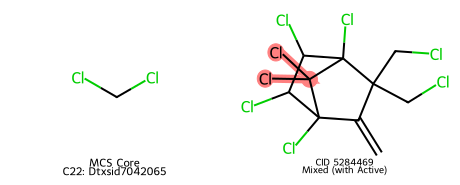

══════════════════════════════════════════════════════════════════════


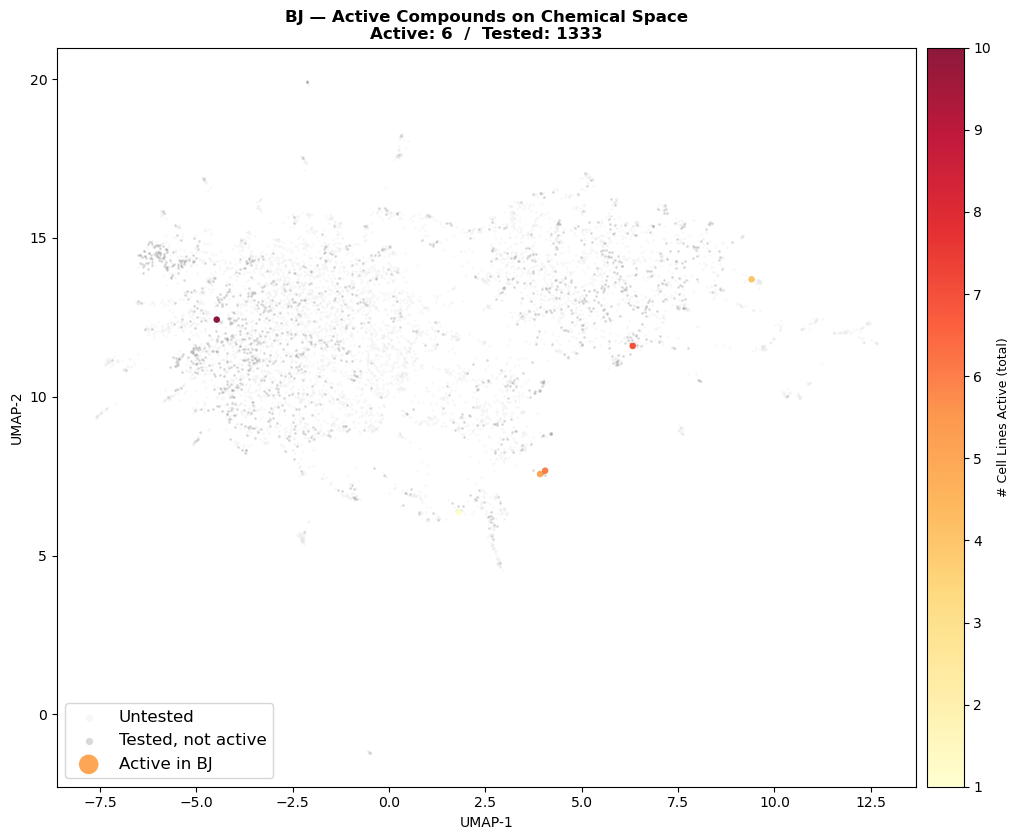

Saved: umap_cellline_AID_658.png

  Active-enriched clusters in BJ (active_frac >= 20%, n >= 5):
     C#  PubChem Name                         MCS SMILES                                          act_here  total_act_frac
  ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  C  22  Dtxsid7042065                        ClCCl                                                      2  20.8%

  C22 (Dtxsid7042065) — MCS core + active reps in BJ:


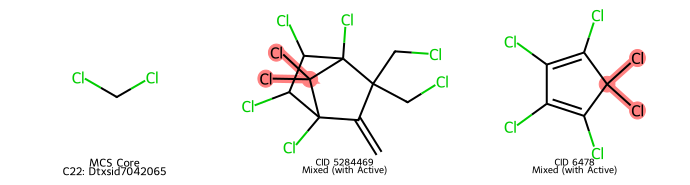

══════════════════════════════════════════════════════════════════════


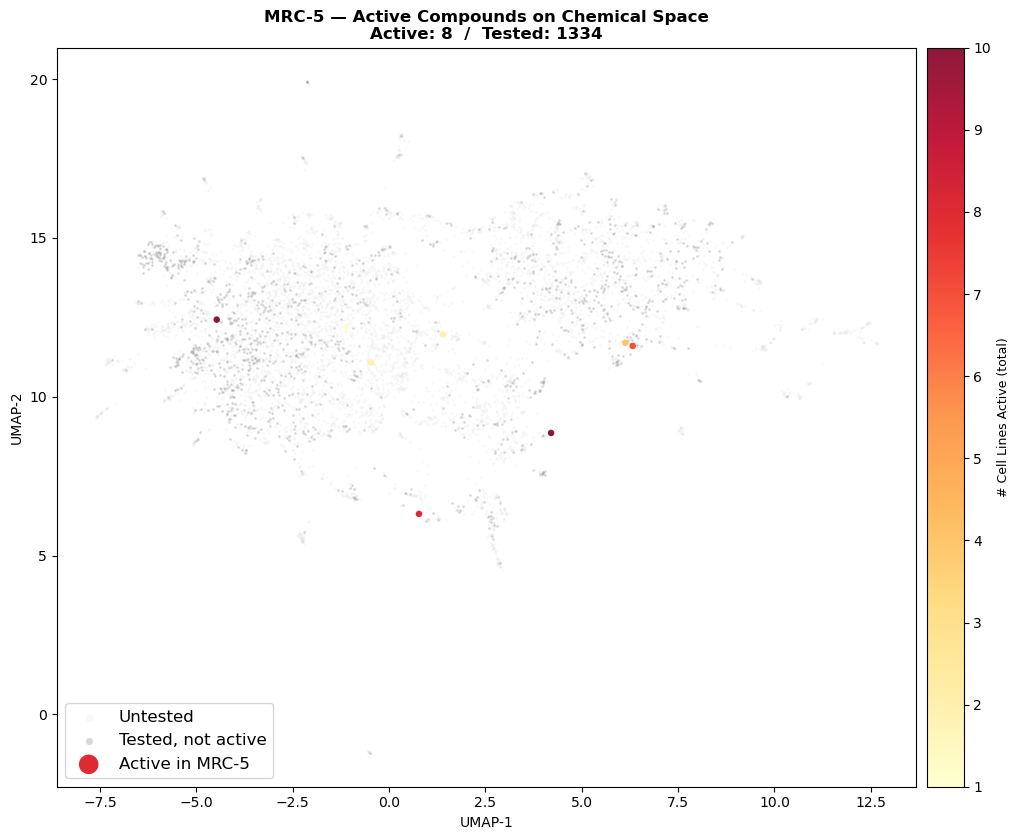

Saved: umap_cellline_AID_659.png
══════════════════════════════════════════════════════════════════════


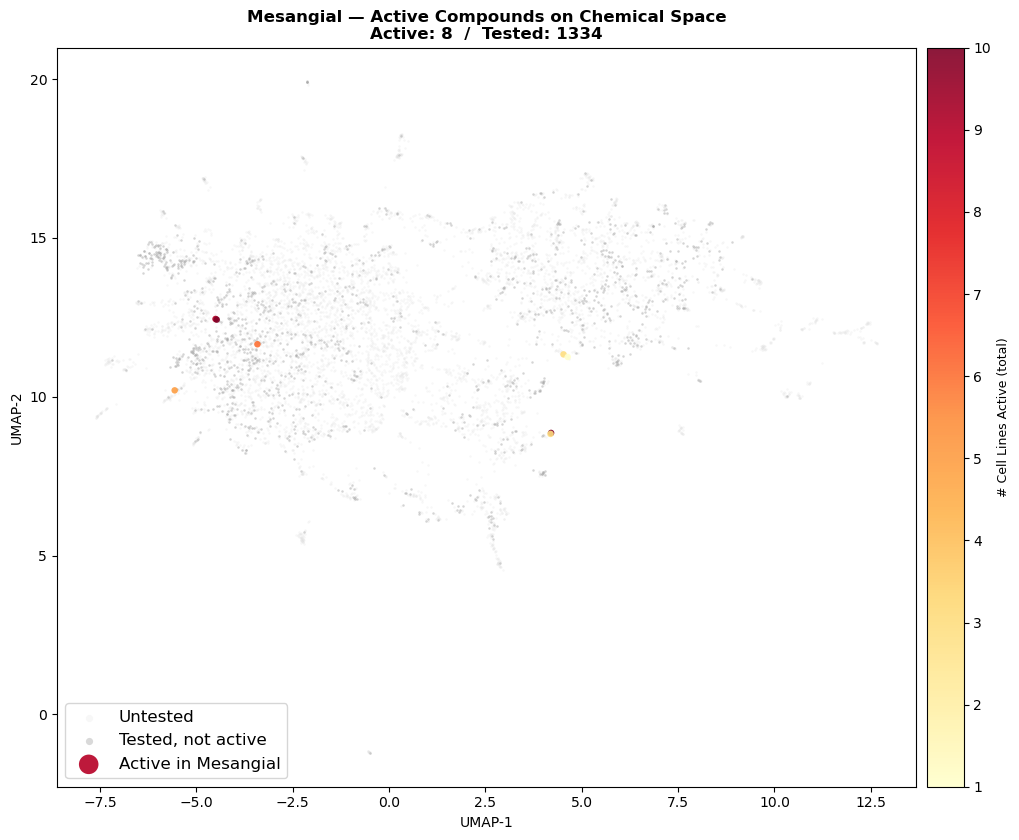

Saved: umap_cellline_AID_660.png
══════════════════════════════════════════════════════════════════════


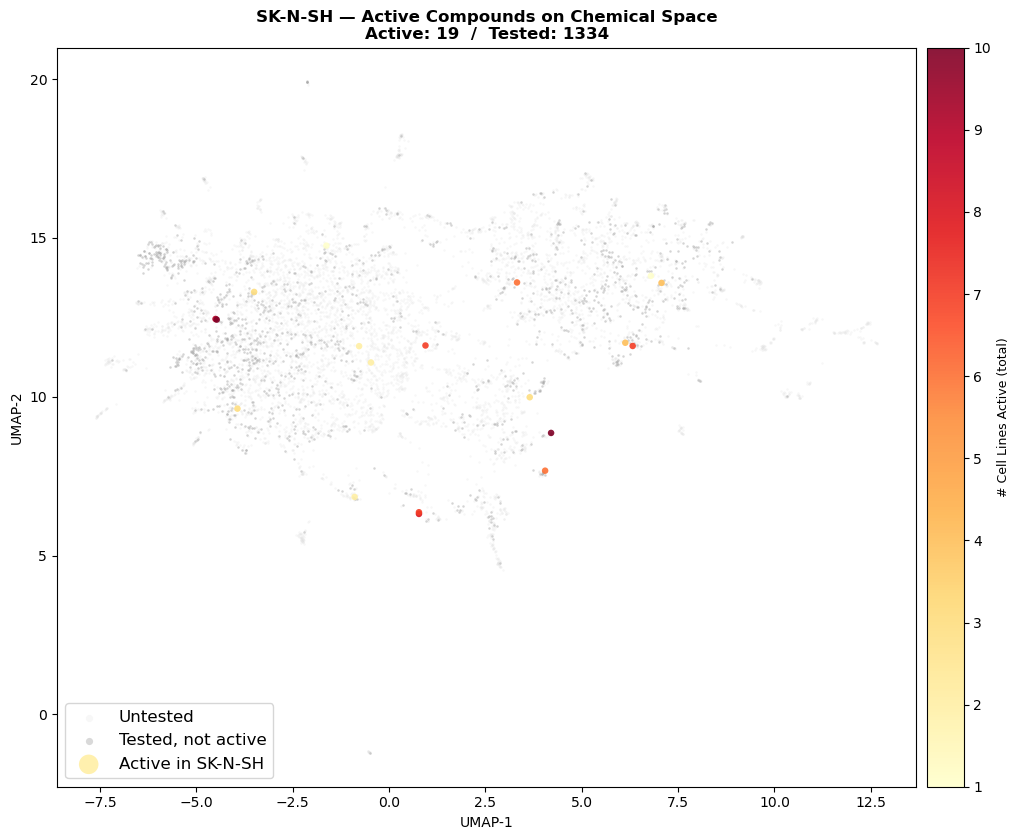

Saved: umap_cellline_AID_661.png

  Active-enriched clusters in SK-N-SH (active_frac >= 20%, n >= 5):
     C#  PubChem Name                         MCS SMILES                                          act_here  total_act_frac
  ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  C  22  Dtxsid7042065                        ClCCl                                                      1  20.8%

  C22 (Dtxsid7042065) — MCS core + active reps in SK-N-SH:


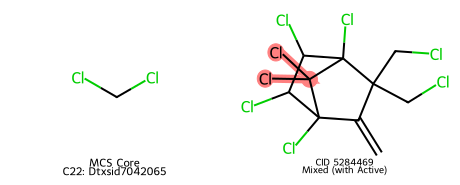

══════════════════════════════════════════════════════════════════════


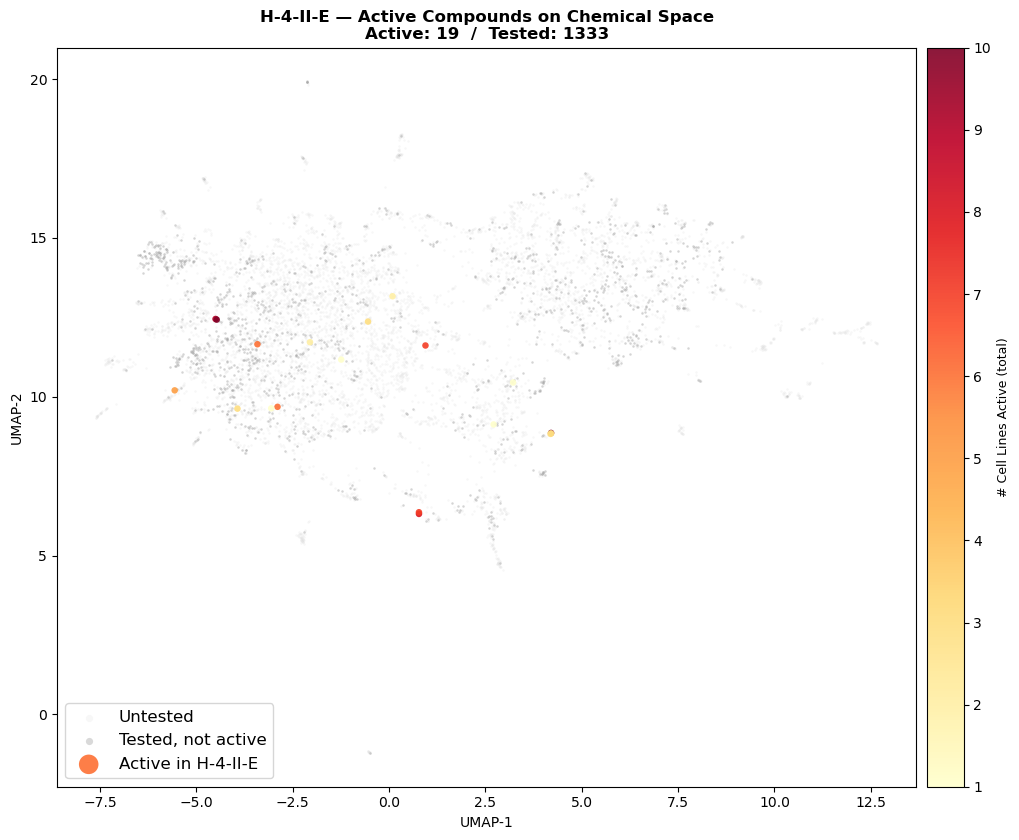

Saved: umap_cellline_AID_663.png
══════════════════════════════════════════════════════════════════════


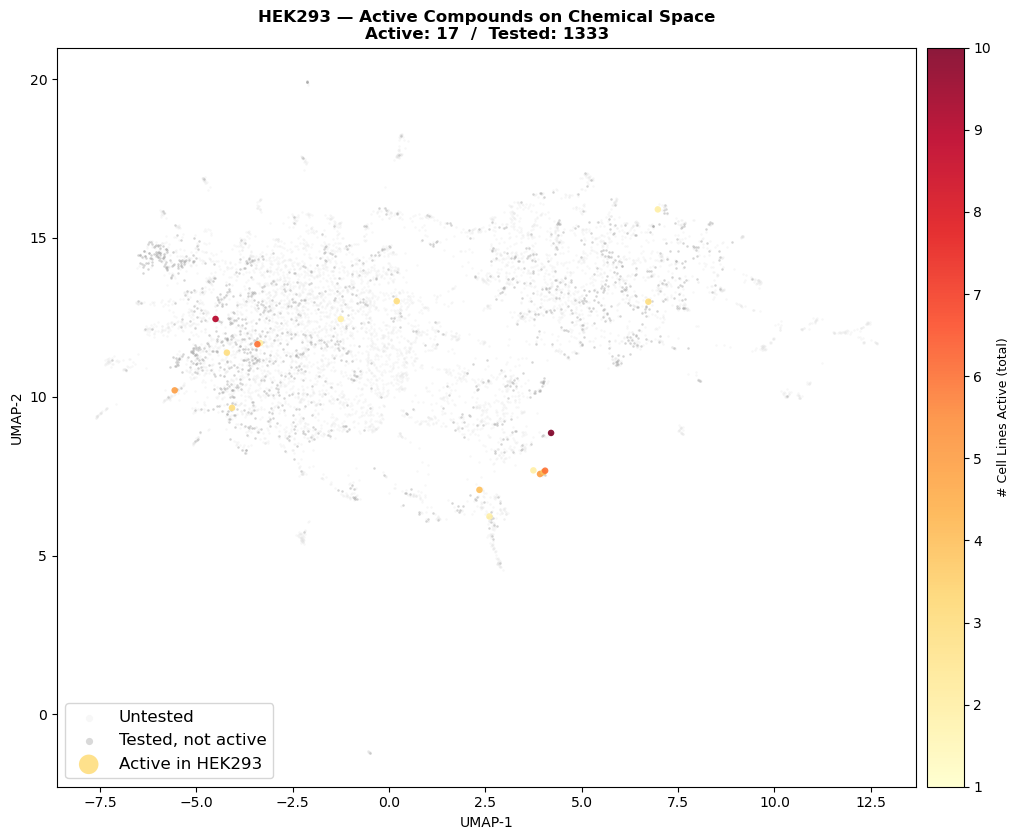

Saved: umap_cellline_AID_664.png

  Active-enriched clusters in HEK293 (active_frac >= 20%, n >= 5):
     C#  PubChem Name                         MCS SMILES                                          act_here  total_act_frac
  ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  C  22  Dtxsid7042065                        ClCCl                                                      4  20.8%

  C22 (Dtxsid7042065) — MCS core + active reps in HEK293:


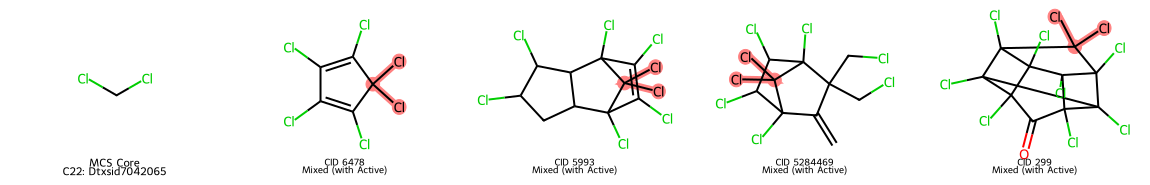

══════════════════════════════════════════════════════════════════════


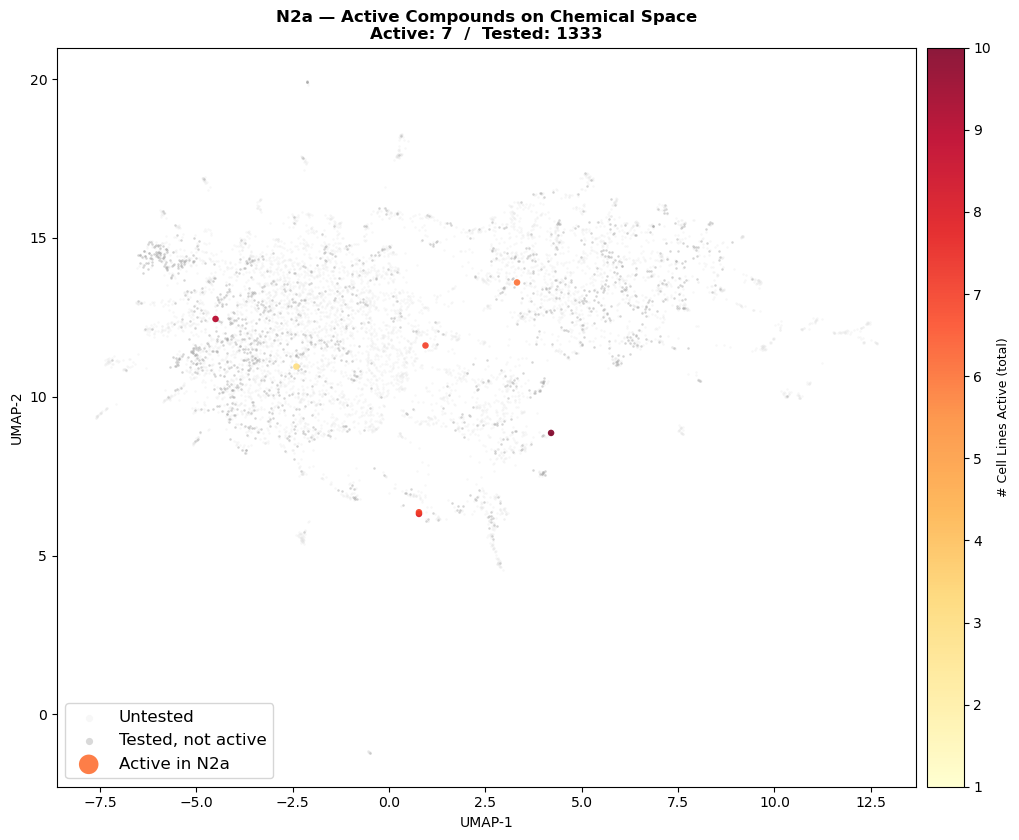

Saved: umap_cellline_AID_665.png
══════════════════════════════════════════════════════════════════════


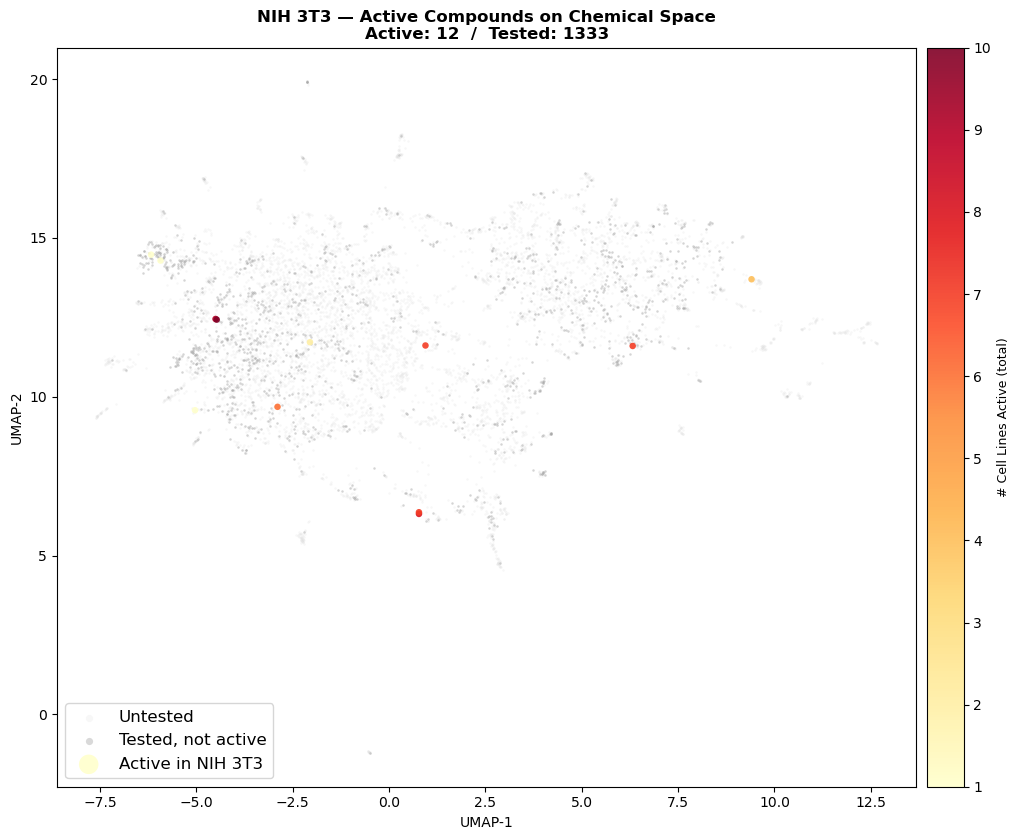

Saved: umap_cellline_AID_666.png
══════════════════════════════════════════════════════════════════════


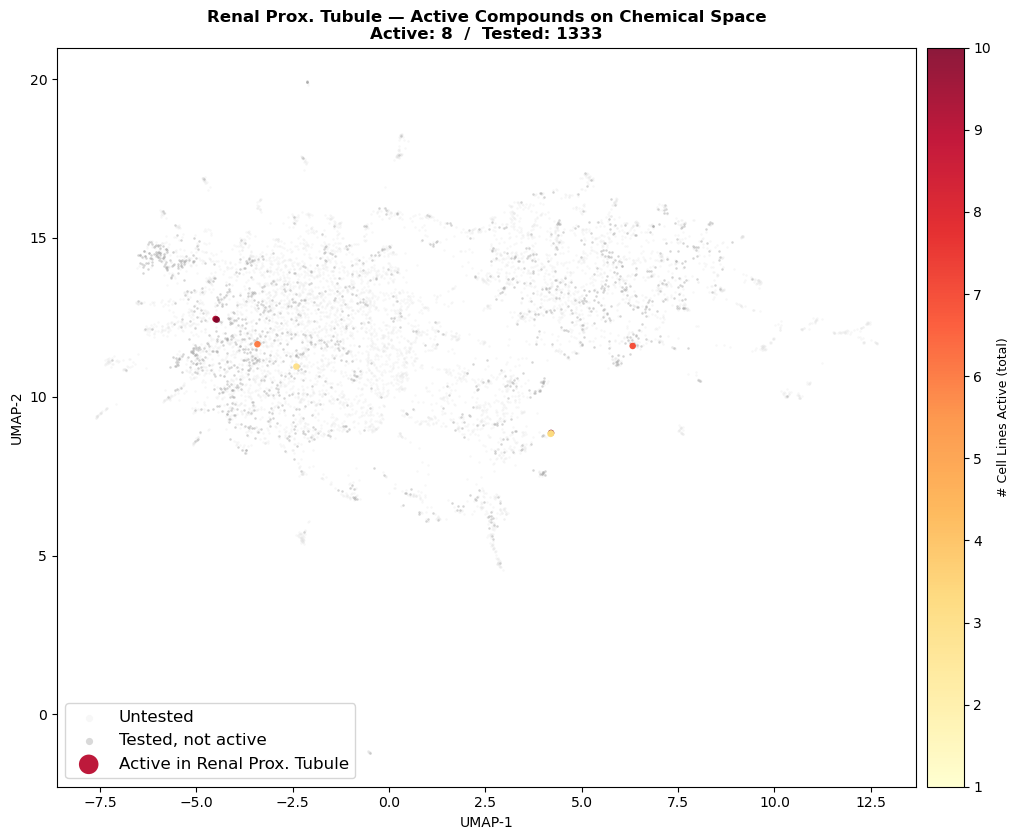

Saved: umap_cellline_AID_667.png
══════════════════════════════════════════════════════════════════════


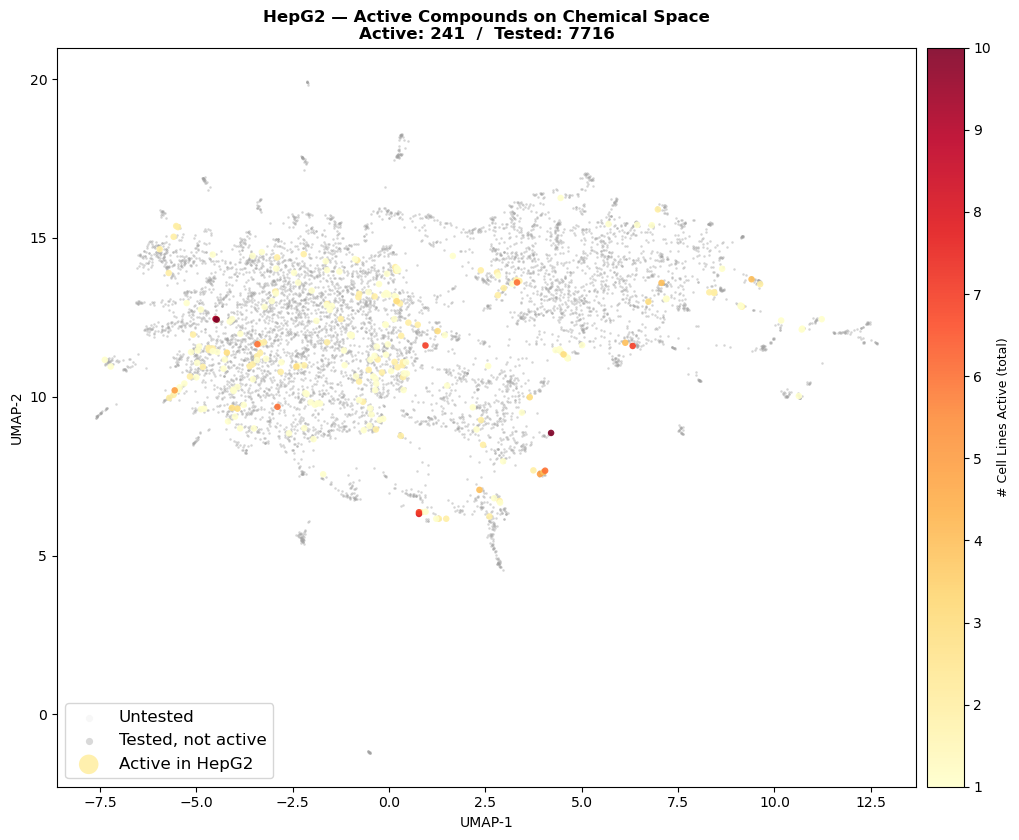

Saved: umap_cellline_combined_hepg2_casepase_csv.png

  Active-enriched clusters in HepG2 (active_frac >= 20%, n >= 5):
     C#  PubChem Name                         MCS SMILES                                          act_here  total_act_frac
  ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  C  22  Dtxsid7042065                        ClCCl                                                      4  20.8%
  C  32  Caswell No. 866A                     —                                                          3  30.8%
  C  39  Dtxsid0047905                        O=[SH](=O)C(F)(F)F                                         1  25.0%

  C22 (Dtxsid7042065) — MCS core + active reps in HepG2:


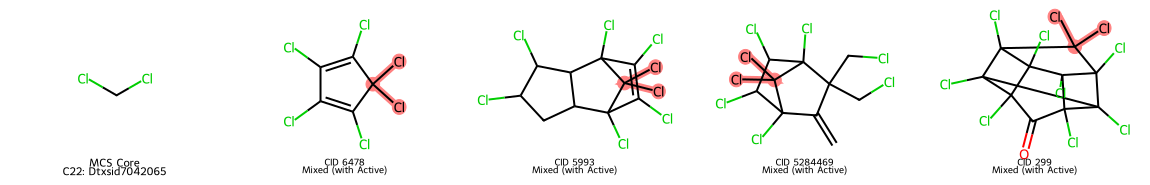


  C32 (Caswell No. 866A) — MCS core + active reps in HepG2:


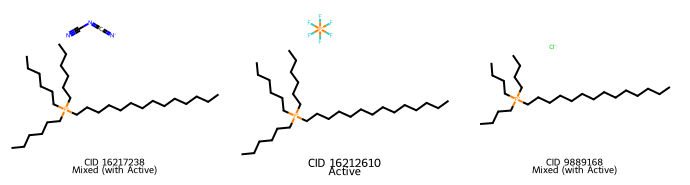


  C39 (Dtxsid0047905) — MCS core + active reps in HepG2:


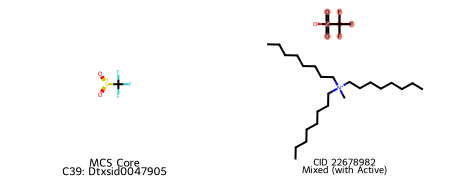

══════════════════════════════════════════════════════════════════════


=== Extra Figure: HepG2 + CHO-K1 Combined Active-Compound Clusters ===

HepG2-only active:  163
CHO-K1-only active: 37
Both active:        78


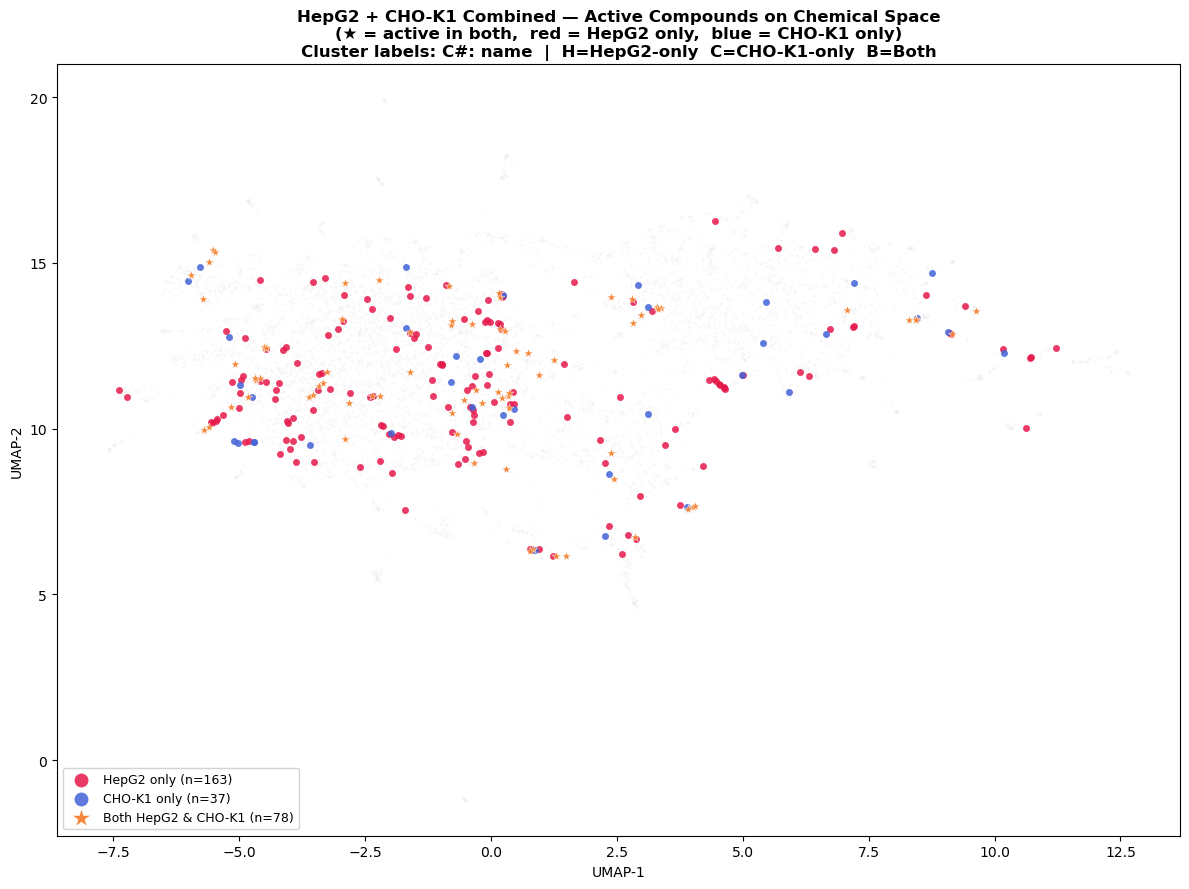

Saved: umap_hepg2_chok1_combined.png

Clusters containing actives from BOTH HepG2 and CHO-K1 (10):
  C0: Ethyl Heptanoate                     HepG2=31  CHO-K1=21  MCS=—
  C1: Ethyl Benzoate                       HepG2=166  CHO-K1=74  MCS=—
  C2: Delta-Octanolactone                  HepG2=9  CHO-K1=4  MCS=—
  C14: Dtac                                 HepG2=2  CHO-K1=1  MCS=CN(C)C
  C16: Cortodoxone                          HepG2=5  CHO-K1=2  MCS=CC12CCCCC1CCC2
  C17: Trehalose, Dihydrate                 HepG2=8  CHO-K1=5  MCS=—
  C22: Dtxsid7042065                        HepG2=4  CHO-K1=4  MCS=ClCCl
  C32: Caswell No. 866A                     HepG2=3  CHO-K1=2  MCS=—
  C37: Codeine                              HepG2=1  CHO-K1=1  MCS=Oc1ccc2c(c1)C1CCNC(C2)C1
  C39: Dtxsid0047905                        HepG2=1  CHO-K1=1  MCS=O=[SH](=O)C(F)(F)F

MCS cores of shared HepG2+CHO-K1 clusters:


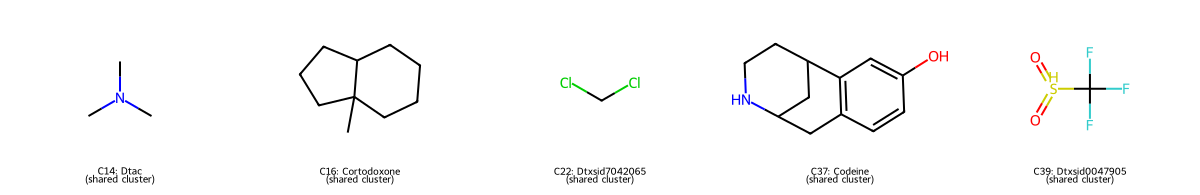

In [36]:
# ── Section 10 (revised): Per-cell-line UMAP + cluster annotation + MCS verification ────────────

ACTIVE_FRAC_THRESHOLD_CL = 0.20
MIN_CLUSTER_SIZE_CL      = 5

# ── Precompute MCS core mol for every non-noise cluster (for verification) ───
print("Precomputing MCS cores for all clusters (this may take ~1-2 min)...")
cluster_mcs_mol  = {}   # cl -> RDKit mol (MCS core) or None
cluster_mcs_smi  = {}   # cl -> SMILES string or None
for cl in sorted(c for c in gvalid['cluster'].unique() if c != -1):
    sub  = gvalid[gvalid['cluster'] == cl]
    mols = [m for m in sub['mol'].tolist() if m is not None][:30]
    core = get_mcs_core(mols)
    cluster_mcs_mol[cl] = core
    cluster_mcs_smi[cl] = Chem.MolToSmiles(core) if core else None

print(f"  MCS found for {sum(1 for v in cluster_mcs_mol.values() if v is not None)} / "
      f"{len(cluster_mcs_mol)} clusters")

# ── Global verification table ────────────────────────────────────────────────
print("\n=== Cluster Name Verification: PubChem representative name vs MCS SMILES ===")
print(f"{'Cluster':>8}  {'PubChem Rep Name':<38}  MCS SMILES")
print("─" * 110)
for cl in sorted(cluster_mcs_mol):
    pub_name = cl_name_map.get(cl, 'N/A')
    mcs_smi  = cluster_mcs_smi.get(cl) or '—'
    print(f"C{cl:>6}  {pub_name:<38}  {mcs_smi}")

# ── ASSAY_COLS_GRID (from previous section) ───────────────────────────────────
SKIP2 = {'PUBCHEM_CID','pattern','behavior','SMILES','mol',
          'behavior_category','n_active_celllines','fp','umap_x','umap_y','cluster'}
ASSAY_COLS_GRID = [c for c in gvalid.columns if c not in SKIP2]

CELLLINE_NAMES = {
    'AID_1346980':                'CHO-K1',
    'AID_655':                    'Jurkat',
    'AID_656':                    'HUV-EC-C',
    'AID_657':                    'SHSY5Y',
    'AID_658':                    'BJ',
    'AID_659':                    'MRC-5',
    'AID_660':                    'Mesangial',
    'AID_661':                    'SK-N-SH',
    'AID_663':                    'H-4-II-E',
    'AID_664':                    'HEK293',
    'AID_665':                    'N2a',
    'AID_666':                    'NIH 3T3',
    'AID_667':                    'Renal Prox. Tubule',
    'combined_hepg2_casepase.csv':'HepG2',
}

# ── Per-cell-line figure loop ─────────────────────────────────────────────────
for col in ASSAY_COLS_GRID:
    cl_label = CELLLINE_NAMES.get(col, col)

    mask_active            = gvalid[col] == 'Active'
    mask_tested_not_active = gvalid[col].notna() & ~mask_active
    n_active = mask_active.sum()
    n_tested = gvalid[col].notna().sum()

    # ── UMAP scatter ─────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(11, 8.5))

    ax.scatter(gvalid['umap_x'], gvalid['umap_y'],
               c='#e0e0e0', s=3, alpha=0.25, linewidths=0, zorder=1,
               label='Untested')
    ax.scatter(gvalid.loc[mask_tested_not_active, 'umap_x'],
               gvalid.loc[mask_tested_not_active, 'umap_y'],
               c='#a0a0a0', s=3, alpha=0.40, linewidths=0, zorder=2,
               label='Tested, not active')
    sc = ax.scatter(gvalid.loc[mask_active, 'umap_x'],
                    gvalid.loc[mask_active, 'umap_y'],
                    c=gvalid.loc[mask_active, 'n_active_celllines'],
                    cmap='YlOrRd', vmin=1, vmax=10,
                    s=22, alpha=0.9, linewidths=0, zorder=3,
                    label=f'Active in {cl_label}')
    cb = plt.colorbar(sc, ax=ax, pad=0.01)
    cb.set_label('# Cell Lines Active (total)', fontsize=9)
    cb.set_ticks(range(1, 11))

    # Clusters with ≥1 active in this cell line (needed for MCS section below)
    active_sub    = gvalid[mask_active & (gvalid['cluster'] != -1)]
    act_cl_counts = active_sub['cluster'].value_counts()

    ax.set_title(
        f'{cl_label} — Active Compounds on Chemical Space\n'
        f'Active: {n_active}  /  Tested: {n_tested}',

        fontsize=12, fontweight='bold')
    ax.set_xlabel('UMAP-1', fontsize=10)
    ax.set_ylabel('UMAP-2', fontsize=10)
    ax.legend(fontsize=12, loc='lower left', markerscale=3)
    plt.tight_layout()

    safe_col = col.replace('.', '_').replace('/', '_')
    fname = RESULTS + f'umap_cellline_{safe_col}.png'
    plt.savefig(fname, dpi=140, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved: umap_cellline_{safe_col}.png')

    # ── MCS verification for active-enriched clusters in this cell line ──────
    ae_here = [
        cl for cl in act_cl_counts.index
        if cl in comp_df.index
        and comp_df.loc[cl, 'n'] >= MIN_CLUSTER_SIZE_CL
        and comp_df.loc[cl, 'active_frac'] >= ACTIVE_FRAC_THRESHOLD_CL
    ]

    if ae_here:
        print(f'\n  Active-enriched clusters in {cl_label} '
              f'(active_frac >= {ACTIVE_FRAC_THRESHOLD_CL:.0%}, n >= {MIN_CLUSTER_SIZE_CL}):')
        print(f"  {'C#':>5}  {'PubChem Name':<35}  {'MCS SMILES':<50}  act_here  total_act_frac")
        print("  " + "─" * 115)
        for cl in sorted(ae_here, key=lambda c: -act_cl_counts[c]):
            pub_name    = cl_name_map.get(cl, 'N/A')
            mcs_smi     = cluster_mcs_smi.get(cl) or '—'
            n_act_here  = act_cl_counts[cl]
            act_frac    = comp_df.loc[cl, 'active_frac']
            print(f"  C{cl:>4}  {pub_name:<35}  {mcs_smi:<50}  {n_act_here:>8}  {act_frac:.1%}")

        # Draw MCS core + active representatives side-by-side
        for cl in sorted(ae_here, key=lambda c: -act_cl_counts[c]):
            pub_name = cl_name_map.get(cl, f'C{cl}')
            core     = cluster_mcs_mol.get(cl)
            # Pick active compounds in this CL from this cluster
            sub_act = gvalid[(gvalid['cluster'] == cl) & mask_active].copy()
            if len(sub_act) == 0:
                sub_act = gvalid[gvalid['cluster'] == cl].copy()
            reps = pick_central(sub_act, n_max=4)

            draw_mols, draw_legs, draw_hi = [], [], []
            if core is not None:
                draw_mols.append(core)
                draw_legs.append(f'MCS Core\nC{cl}: {pub_name}')
                draw_hi.append([])
            for _, row in reps.iterrows():
                if row['mol'] is None:
                    continue
                draw_mols.append(row['mol'])
                draw_legs.append(f"CID {int(row['PUBCHEM_CID'])}\n{row['behavior_category']}")
                if core is not None:
                    try:
                        draw_hi.append(list(row['mol'].GetSubstructMatch(core)))
                    except Exception:
                        draw_hi.append([])
                else:
                    draw_hi.append([])

            if draw_mols:
                print(f"\n  C{cl} ({pub_name}) — MCS core + active reps in {cl_label}:")
                img = Draw.MolsToGridImage(
                    draw_mols, molsPerRow=min(5, len(draw_mols)),
                    subImgSize=(230, 185), legends=draw_legs,
                    highlightAtomLists=draw_hi, returnPNG=False)
                display(img)

    print('═' * 70)

# ─────────────────────────────────────────────────────────────────────────────
# Extra figure: HepG2 + CHO-K1 combined cluster view
# ─────────────────────────────────────────────────────────────────────────────
print("\n\n=== Extra Figure: HepG2 + CHO-K1 Combined Active-Compound Clusters ===\n")

hepg2_col = 'combined_hepg2_casepase.csv'
chok1_col = 'AID_1346980'

# Determine membership
is_hepg2  = gvalid[hepg2_col] == 'Active'
is_chok1  = gvalid[chok1_col] == 'Active'
is_both   = is_hepg2 & is_chok1
is_honly  = is_hepg2 & ~is_chok1
is_conly  = is_chok1 & ~is_hepg2
is_either = is_hepg2 | is_chok1

n_honly = is_honly.sum()
n_conly = is_conly.sum()
n_both  = is_both.sum()
print(f"HepG2-only active:  {n_honly}")
print(f"CHO-K1-only active: {n_conly}")
print(f"Both active:        {n_both}")

fig, ax = plt.subplots(figsize=(12, 9))

# Background
ax.scatter(gvalid['umap_x'], gvalid['umap_y'],
           c='#ebebeb', s=3, alpha=0.25, linewidths=0, zorder=1)

# HepG2-only
if is_honly.any():
    ax.scatter(gvalid.loc[is_honly, 'umap_x'], gvalid.loc[is_honly, 'umap_y'],
               c='#e6194b', s=25, alpha=0.85, linewidths=0, zorder=3,
               label=f'HepG2 only (n={n_honly})')
# CHO-K1-only
if is_conly.any():
    ax.scatter(gvalid.loc[is_conly, 'umap_x'], gvalid.loc[is_conly, 'umap_y'],
               c='#4363d8', s=25, alpha=0.85, linewidths=0, zorder=3,
               label=f'CHO-K1 only (n={n_conly})')
# Both
if is_both.any():
    ax.scatter(gvalid.loc[is_both, 'umap_x'], gvalid.loc[is_both, 'umap_y'],
               c='#f58231', s=45, marker='*', alpha=0.95, linewidths=0.3,
               edgecolors='white', zorder=4,
               label=f'Both HepG2 & CHO-K1 (n={n_both})')

ax.set_title(
    'HepG2 + CHO-K1 Combined — Active Compounds on Chemical Space\n'
    '(★ = active in both,  red = HepG2 only,  blue = CHO-K1 only)\n'
    'Cluster labels: C#: name  |  H=HepG2-only  C=CHO-K1-only  B=Both',
    fontsize=12, fontweight='bold')
ax.set_xlabel('UMAP-1', fontsize=10)
ax.set_ylabel('UMAP-2', fontsize=10)
ax.legend(fontsize=9, loc='lower left', markerscale=2, framealpha=0.85)
plt.tight_layout()
plt.savefig(RESULTS + 'umap_hepg2_chok1_combined.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()
print('Saved: umap_hepg2_chok1_combined.png')

# Print clusters shared between HepG2 and CHO-K1 actives
shared_clusters = set(
    gvalid.loc[is_hepg2 & (gvalid['cluster'] != -1), 'cluster']
).intersection(
    set(gvalid.loc[is_chok1 & (gvalid['cluster'] != -1), 'cluster'])
)
print(f'\nClusters containing actives from BOTH HepG2 and CHO-K1 ({len(shared_clusters)}):')
for cl in sorted(shared_clusters):
    pub_name = cl_name_map.get(cl, 'N/A')
    mcs_smi  = cluster_mcs_smi.get(cl) or '—'
    n_h = (gvalid[(gvalid['cluster'] == cl) & is_hepg2]).shape[0]
    n_c = (gvalid[(gvalid['cluster'] == cl) & is_chok1]).shape[0]
    print(f'  C{cl}: {pub_name:<35}  HepG2={n_h}  CHO-K1={n_c}  MCS={mcs_smi}')

# Draw shared cluster MCS cores
if shared_clusters:
    shared_mols, shared_legs = [], []
    for cl in sorted(shared_clusters):
        core = cluster_mcs_mol.get(cl)
        if core:
            pub_name = cl_name_map.get(cl, f'C{cl}')
            shared_mols.append(core)
            shared_legs.append(f'C{cl}: {pub_name}\n(shared cluster)')
    if shared_mols:
        print(f'\nMCS cores of shared HepG2+CHO-K1 clusters:')
        img = Draw.MolsToGridImage(
            shared_mols, molsPerRow=min(5, len(shared_mols)),
            subImgSize=(240, 195), legends=shared_legs, returnPNG=False)
        display(img)


---
## Section 11 — Publication-Quality UMAP Grid

3-column layout with larger panels and bigger fonts for use in papers/presentations.

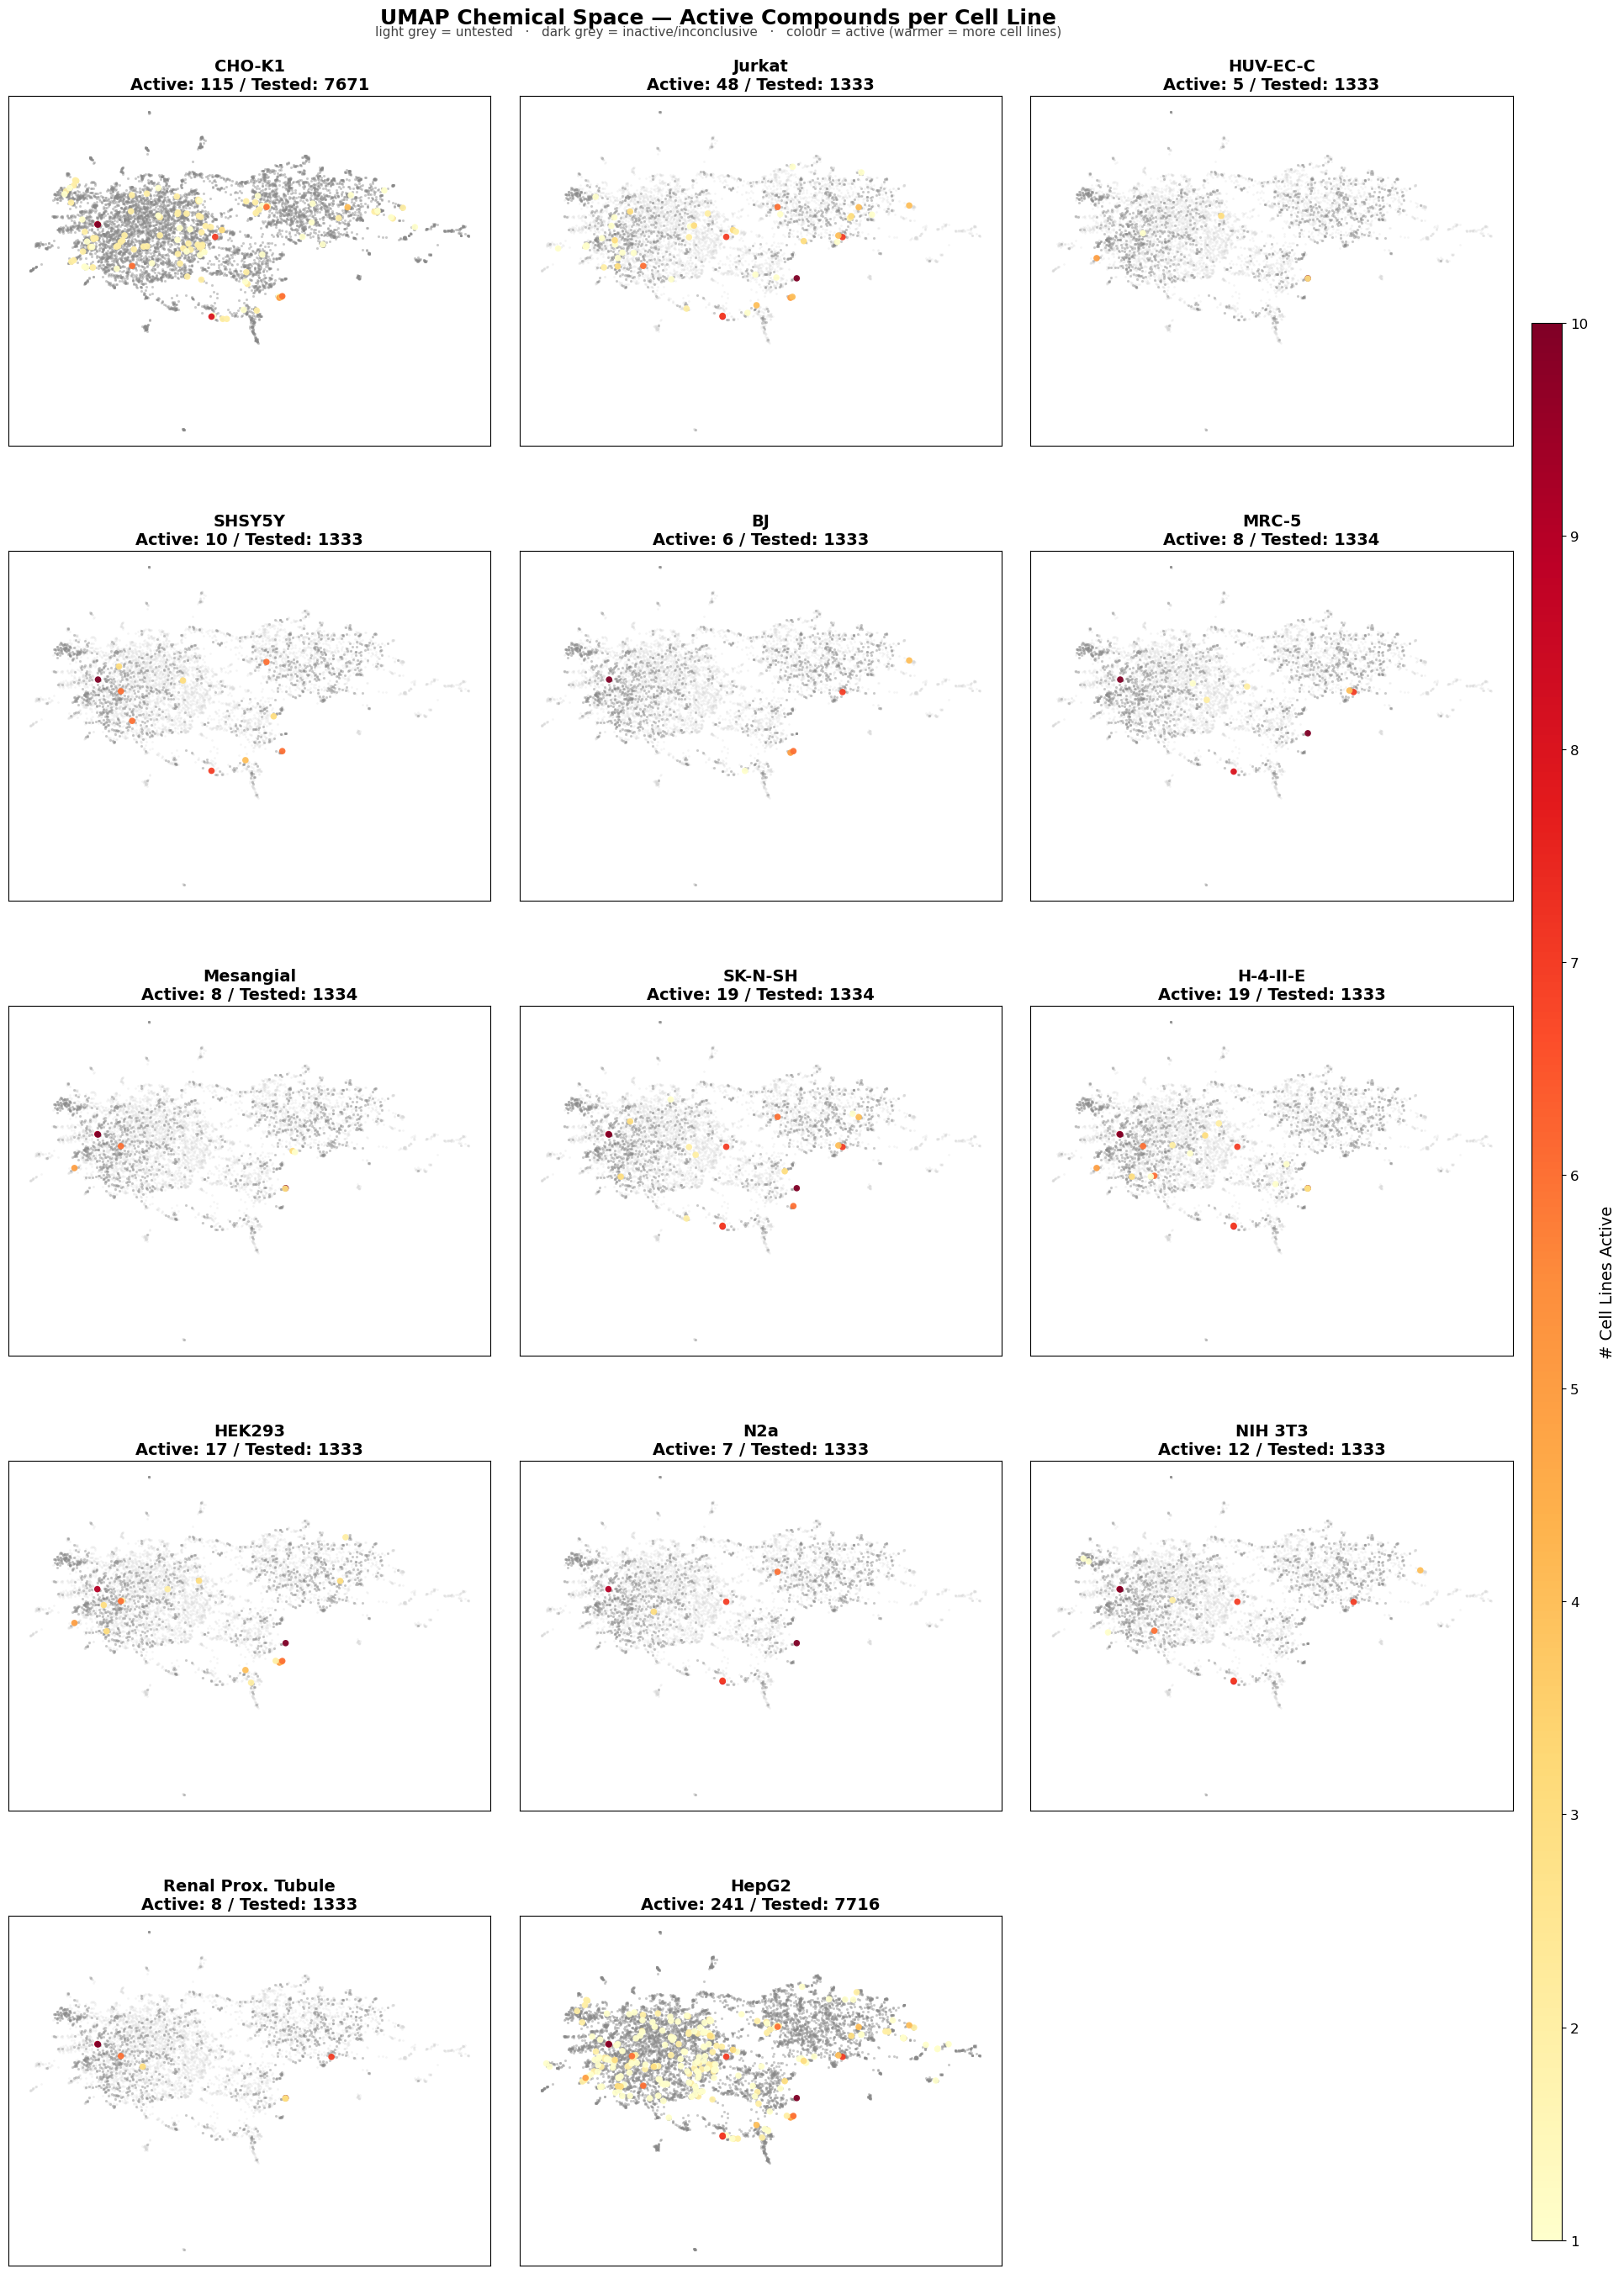

Saved: umap_grid_per_cellline_pub.png


In [37]:
# ── Section 11 — Publication-quality UMAP grid (larger panels, bigger fonts) ─

SKIP3 = {'PUBCHEM_CID','pattern','behavior','SMILES','mol',
          'behavior_category','n_active_celllines','fp','umap_x','umap_y','cluster'}
ASSAY_COLS_PUB = [c for c in gvalid.columns if c not in SKIP3]

CELLLINE_NAMES_PUB = {
    'AID_1346980':                'CHO-K1',
    'AID_655':                    'Jurkat',
    'AID_656':                    'HUV-EC-C',
    'AID_657':                    'SHSY5Y',
    'AID_658':                    'BJ',
    'AID_659':                    'MRC-5',
    'AID_660':                    'Mesangial',
    'AID_661':                    'SK-N-SH',
    'AID_663':                    'H-4-II-E',
    'AID_664':                    'HEK293',
    'AID_665':                    'N2a',
    'AID_666':                    'NIH 3T3',
    'AID_667':                    'Renal Prox. Tubule',
    'combined_hepg2_casepase.csv':'HepG2',
}

ncols = 3
nrows = 5   # 15 panels for 14 cell lines; last hidden

# Larger per-panel size for paper
panel_w, panel_h = 7.5, 6.0
fig, axes = plt.subplots(nrows, ncols,
                         figsize=(ncols * panel_w, nrows * panel_h))
axes_flat = axes.flatten()

for idx, col in enumerate(ASSAY_COLS_PUB):
    ax   = axes_flat[idx]
    name = CELLLINE_NAMES_PUB.get(col, col)

    mask_active            = gvalid[col] == 'Active'
    mask_tested_not_active = gvalid[col].notna() & ~mask_active
    n_active = mask_active.sum()
    n_tested = gvalid[col].notna().sum()

    # Background: untested
    ax.scatter(gvalid['umap_x'], gvalid['umap_y'],
               c='#d9d9d9', s=4, alpha=0.25, linewidths=0, zorder=1,
               label='Untested')

    # Tested but not active
    ax.scatter(gvalid.loc[mask_tested_not_active, 'umap_x'],
               gvalid.loc[mask_tested_not_active, 'umap_y'],
               c='#888888', s=5, alpha=0.40, linewidths=0, zorder=2,
               label='Inactive / inconclusive')

    # Active — coloured by total n_active_celllines
    sc = ax.scatter(gvalid.loc[mask_active, 'umap_x'],
                    gvalid.loc[mask_active, 'umap_y'],
                    c=gvalid.loc[mask_active, 'n_active_celllines'],
                    cmap='YlOrRd', vmin=1, vmax=10,
                    s=30, alpha=0.95, linewidths=0, zorder=3,
                    label='Active')

    ax.set_title(f'{name}\nActive: {n_active} / Tested: {n_tested}',
                 fontsize=14, fontweight='bold', pad=6)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_linewidth(0.8)

# Hide unused panels
for idx in range(len(ASSAY_COLS_PUB), len(axes_flat)):
    axes_flat[idx].set_visible(False)

# Shared colourbar — placed to the right
cbar_ax = fig.add_axes([0.93, 0.12, 0.016, 0.76])
sm = plt.cm.ScalarMappable(cmap='YlOrRd', norm=plt.Normalize(vmin=1, vmax=10))
sm.set_array([])
cb = fig.colorbar(sm, cax=cbar_ax)
cb.set_label('# Cell Lines Active', fontsize=14, labelpad=10)
cb.set_ticks(range(1, 11))
cb.ax.tick_params(labelsize=12)

fig.suptitle(
    'UMAP Chemical Space — Active Compounds per Cell Line',
    fontsize=18, fontweight='bold', y=1.005)
fig.text(0.5, 0.998,
         'light grey = untested   ·   dark grey = inactive/inconclusive   ·   colour = active (warmer = more cell lines)',
         ha='center', va='top', fontsize=11, color='#444')

plt.subplots_adjust(wspace=0.06, hspace=0.30, right=0.92, top=0.97)
plt.savefig(RESULTS + 'umap_grid_per_cellline_pub.png',
            dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: umap_grid_per_cellline_pub.png')


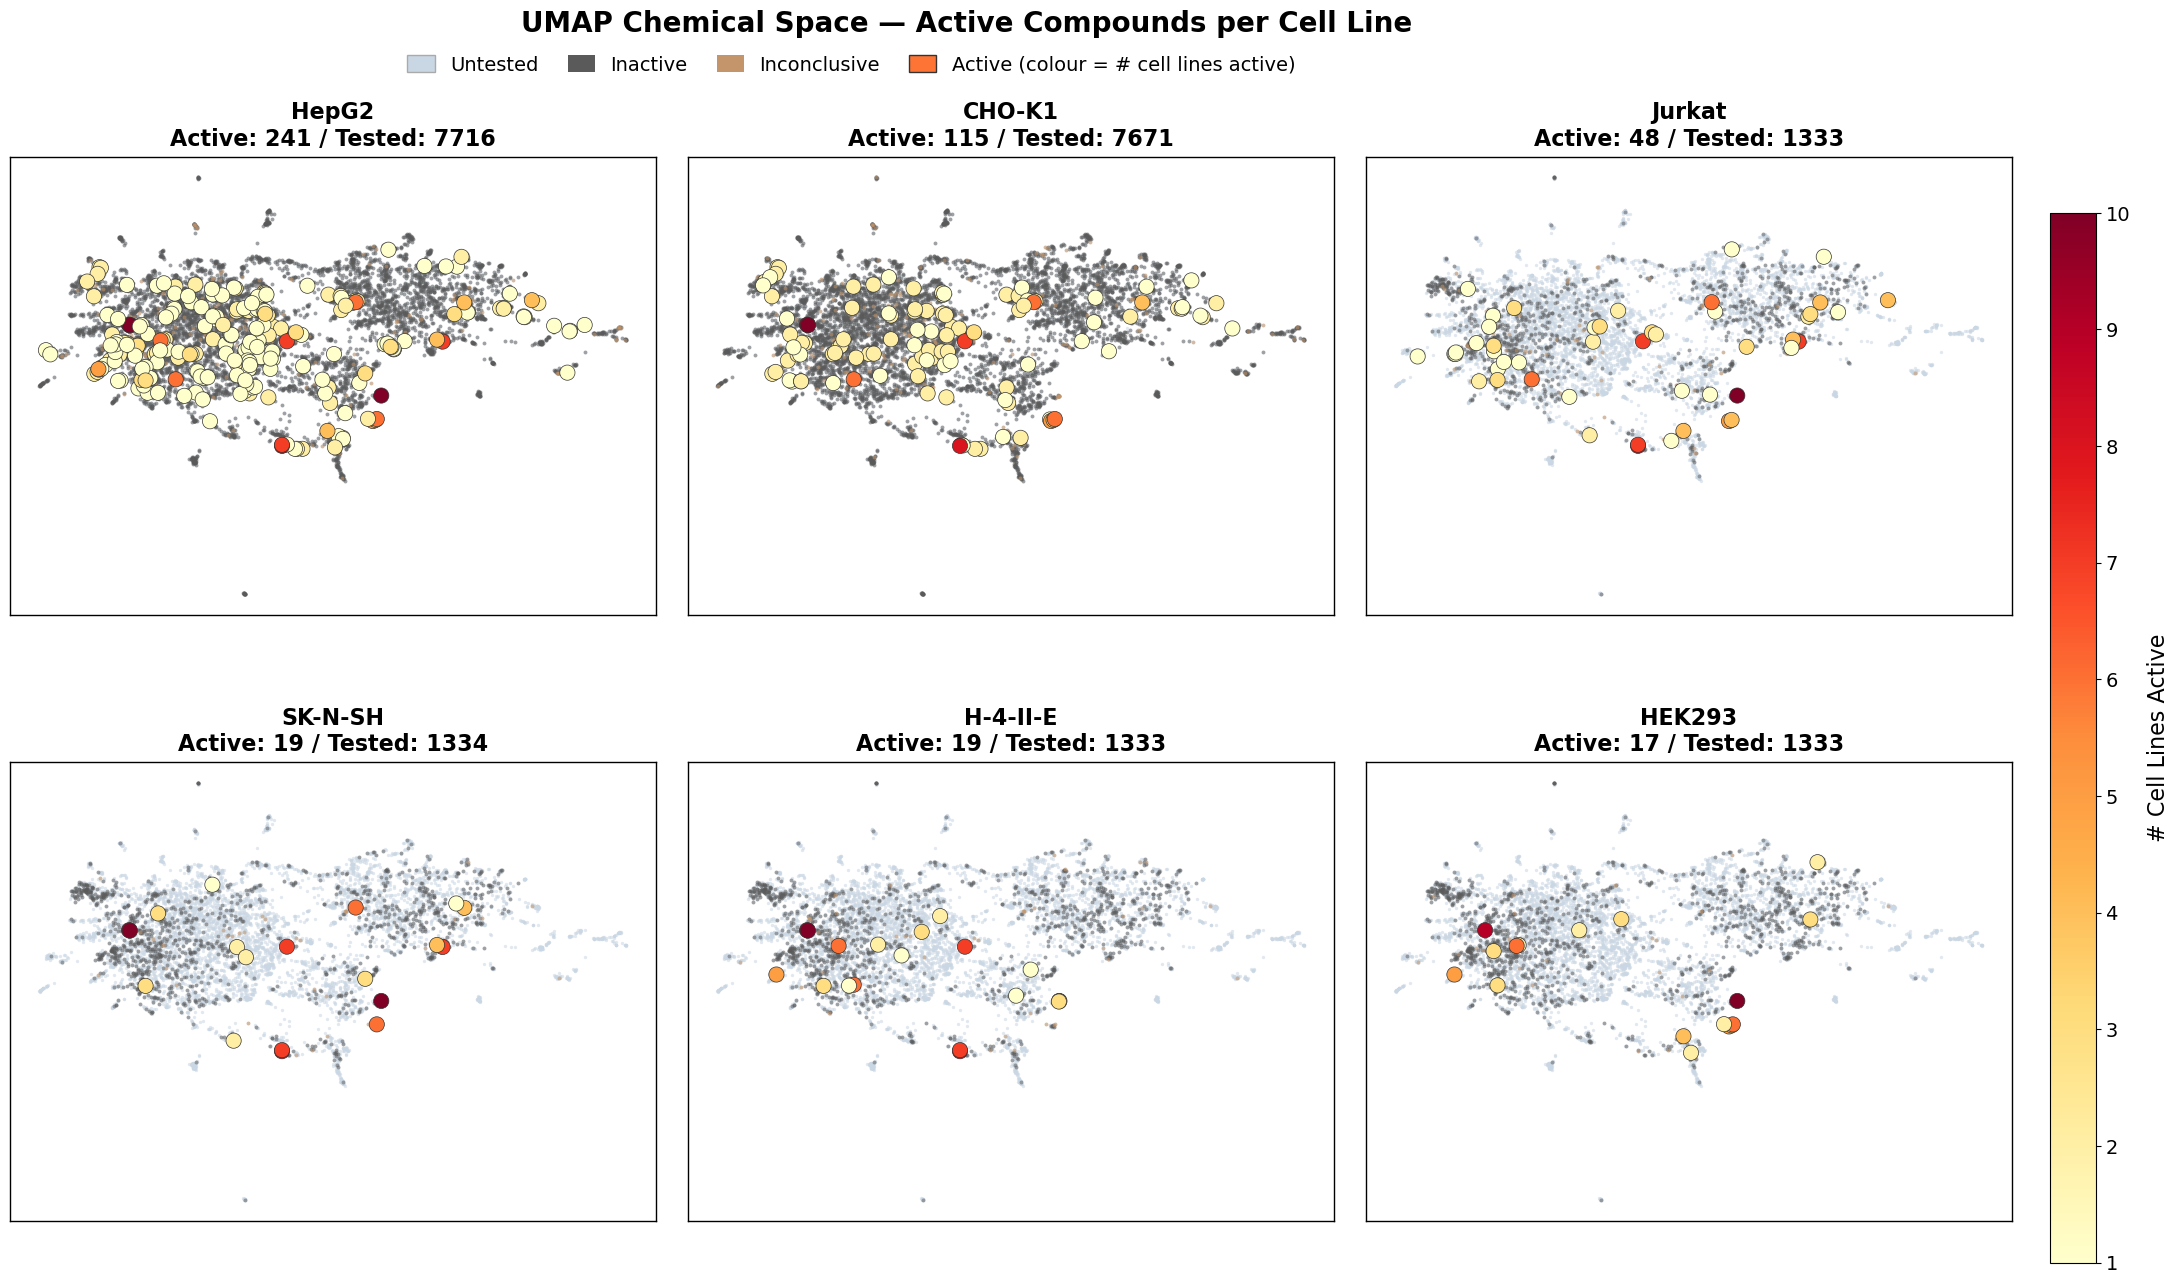

Saved: umap_grid_main_celllines.png


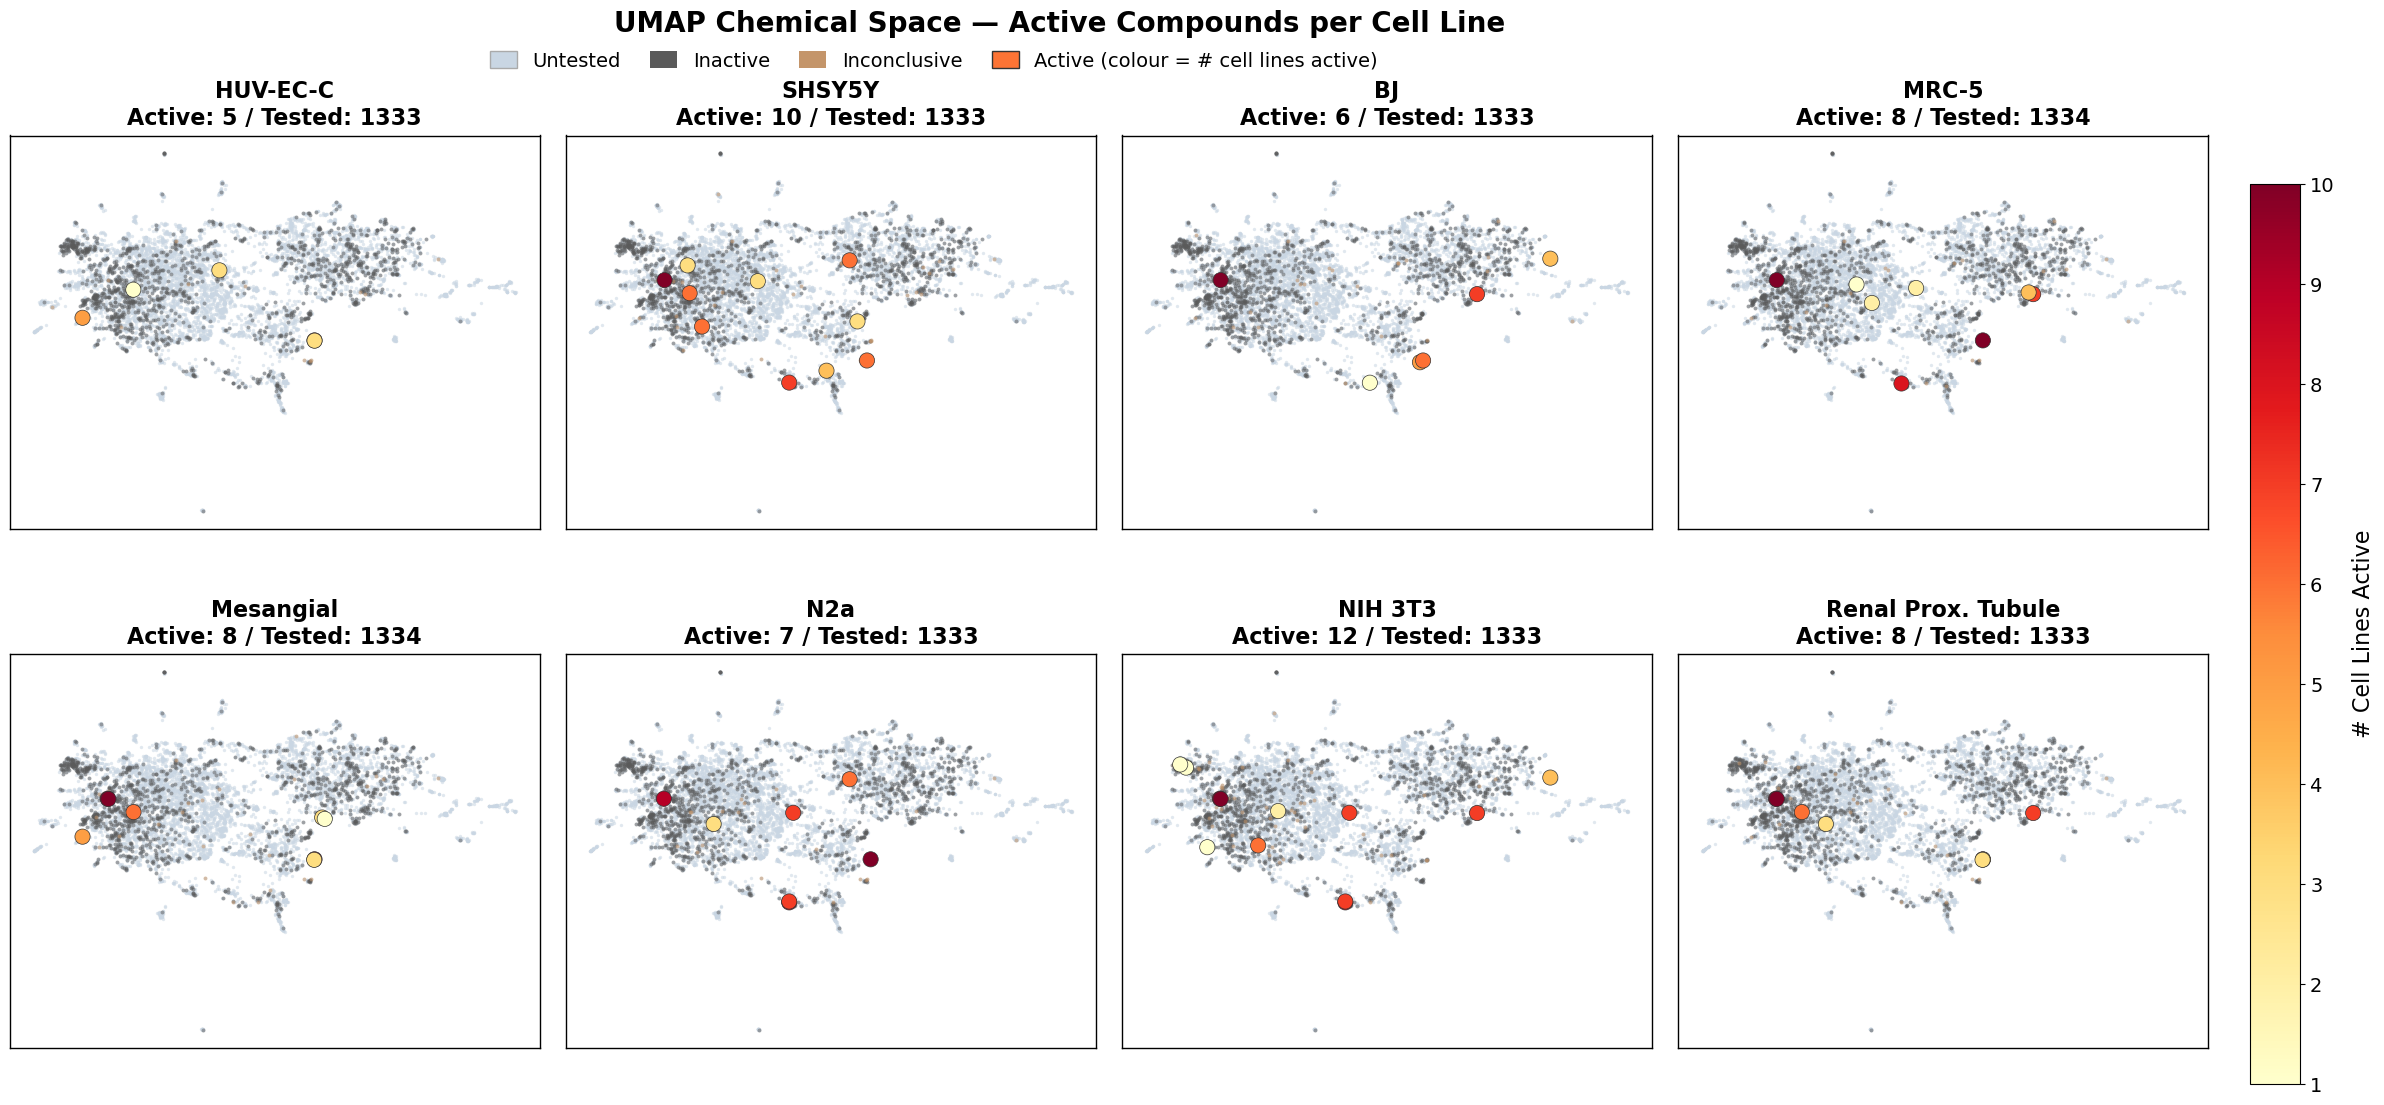

Saved: umap_grid_supp_celllines.png


In [38]:
# ── Section 12 — Split UMAP grids: Main-paper cell lines + Supplementary ──────

MAIN_COLS = [
    'combined_hepg2_casepase.csv',   # HepG2
    'AID_1346980',                    # CHO-K1
    'AID_655',                        # Jurkat
    'AID_661',                        # SK-N-SH
    'AID_663',                        # H-4-II-E
    'AID_664',                        # HEK293
]

SUPP_COLS = [
    'AID_656',   # HUV-EC-C
    'AID_657',   # SHSY5Y
    'AID_658',   # BJ
    'AID_659',   # MRC-5
    'AID_660',   # Mesangial
    'AID_665',   # N2a
    'AID_666',   # NIH 3T3
    'AID_667',   # Renal Prox. Tubule
]

_NAMES = CELLLINE_NAMES_PUB

C_UNTESTED      = '#c9d6e3'   # pale blue-grey
C_INACTIVE      = '#5a5a5a'   # charcoal grey
C_INCONCLUSIVE  = '#c4956a'   # warm amber-brown

def _umap_grid(cols, ncols, panel_w, panel_h, title, fname,
               s_bg=6, s_inactive=8, s_inconc=8, s_active=120):
    import matplotlib.patches as mpatches
    import matplotlib.cm as cm

    nrows = (len(cols) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(ncols * panel_w, nrows * panel_h))
    axes_flat = axes.flatten() if nrows * ncols > 1 else [axes]

    for idx, col in enumerate(cols):
        ax   = axes_flat[idx]
        name = _NAMES.get(col, col)

        mask_active      = gvalid[col] == 'Active'
        mask_inactive    = gvalid[col] == 'Inactive'
        mask_inconc      = gvalid[col] == 'Inconclusive'
        n_active = int(mask_active.sum())
        n_tested = int(gvalid[col].notna().sum())

        # untested — pale blue-grey
        ax.scatter(gvalid['umap_x'], gvalid['umap_y'],
                   c=C_UNTESTED, s=s_bg, alpha=0.55, linewidths=0, zorder=1)
        # inactive — charcoal grey
        ax.scatter(gvalid.loc[mask_inactive, 'umap_x'],
                   gvalid.loc[mask_inactive, 'umap_y'],
                   c=C_INACTIVE, s=s_inactive, alpha=0.50, linewidths=0, zorder=2)
        # inconclusive — warm amber
        ax.scatter(gvalid.loc[mask_inconc, 'umap_x'],
                   gvalid.loc[mask_inconc, 'umap_y'],
                   c=C_INCONCLUSIVE, s=s_inconc, alpha=0.55, linewidths=0, zorder=3)
        # active — large vivid dots with edge
        ax.scatter(gvalid.loc[mask_active, 'umap_x'],
                   gvalid.loc[mask_active, 'umap_y'],
                   c=gvalid.loc[mask_active, 'n_active_celllines'],
                   cmap='YlOrRd', vmin=1, vmax=10,
                   s=s_active, alpha=1.0, linewidths=0.5,
                   edgecolors='#333333', zorder=4)

        ax.set_title(f'{name}\nActive: {n_active} / Tested: {n_tested}',
                     fontsize=16, fontweight='bold', pad=8)
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_linewidth(1.0)

    for idx in range(len(cols), len(axes_flat)):
        axes_flat[idx].set_visible(False)

    plt.subplots_adjust(wspace=0.05, hspace=0.32, right=0.91, top=0.87)

    # colourbar
    cbar_ax = fig.add_axes([0.925, 0.08, 0.018, 0.75])
    sm = plt.cm.ScalarMappable(cmap='YlOrRd', norm=plt.Normalize(vmin=1, vmax=10))
    sm.set_array([])
    cb = fig.colorbar(sm, cax=cbar_ax)
    cb.set_label('# Cell Lines Active', fontsize=16, labelpad=12)
    cb.set_ticks(range(1, 11))
    cb.ax.tick_params(labelsize=14)

    fig.suptitle(title, fontsize=20, fontweight='bold', y=0.975)

    legend_handles = [
        mpatches.Patch(facecolor=C_UNTESTED,     edgecolor='#aaaaaa', label='Untested'),
        mpatches.Patch(facecolor=C_INACTIVE,     edgecolor='none',    label='Inactive'),
        mpatches.Patch(facecolor=C_INCONCLUSIVE, edgecolor='none',    label='Inconclusive'),
        mpatches.Patch(facecolor=cm.YlOrRd(0.55), edgecolor='#333333', label='Active (colour = # cell lines active)'),
    ]
    fig.legend(handles=legend_handles,
               loc='upper center', bbox_to_anchor=(0.455, 0.955),
               ncol=4, fontsize=14, frameon=False,
               handlelength=1.4, handleheight=1.0, columnspacing=1.5)

    plt.savefig(RESULTS + fname, dpi=250, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved: {fname}')


_umap_grid(
    cols=MAIN_COLS, ncols=3, panel_w=8.5, panel_h=7.0,
    title='UMAP Chemical Space — Active Compounds per Cell Line',
    fname='umap_grid_main_celllines.png',
)

_umap_grid(
    cols=SUPP_COLS, ncols=4, panel_w=7.0, panel_h=6.0,
    title='UMAP Chemical Space — Active Compounds per Cell Line',
    fname='umap_grid_supp_celllines.png',
)


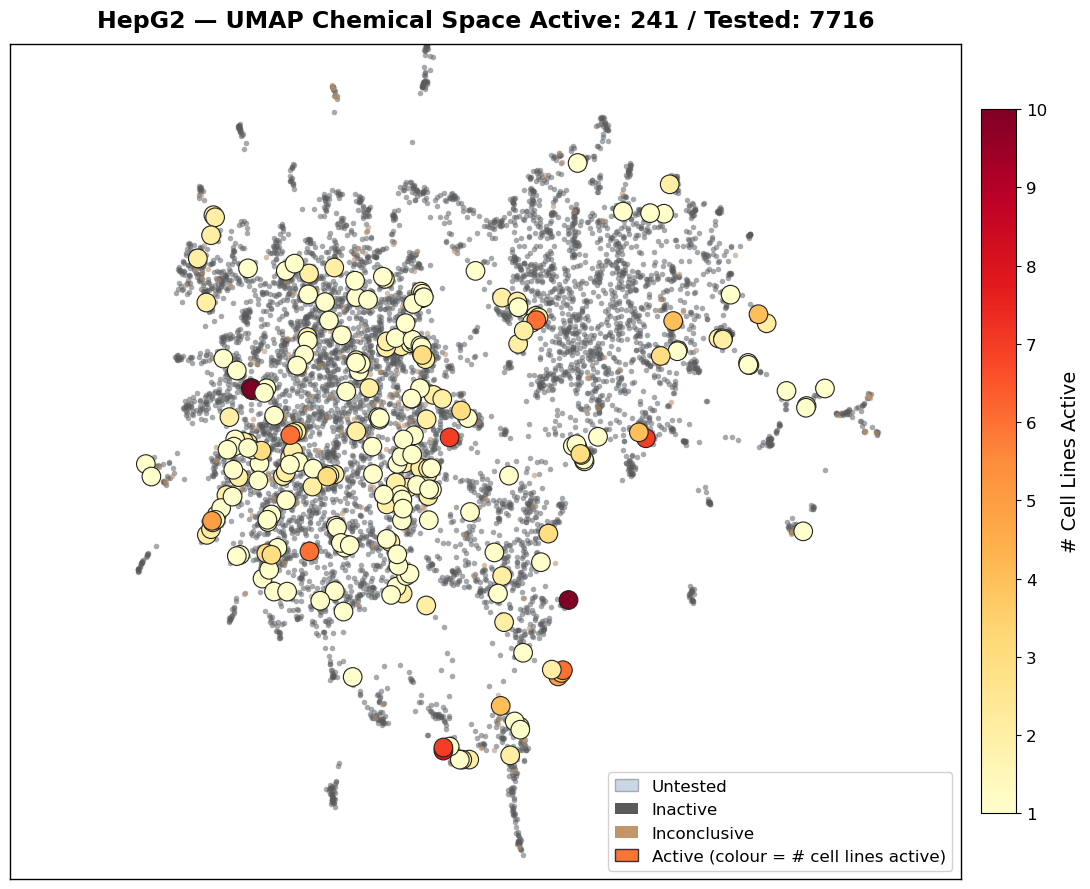

Saved: umap_hepg2_zoomed.png


In [41]:
# ── Section 13 — HepG2-Only UMAP: Zoomed Single Panel ─────────────────────────
import matplotlib.patches as mpatches
import matplotlib.cm as cm
from matplotlib.patches import FancyArrowPatch

HEPG2_COL = 'combined_hepg2_casepase.csv'

mask_active   = gvalid[HEPG2_COL] == 'Active'
mask_inactive = gvalid[HEPG2_COL] == 'Inactive'
mask_inconc   = gvalid[HEPG2_COL] == 'Inconclusive'
mask_untested = gvalid[HEPG2_COL].isna()

n_active = int(mask_active.sum())
n_tested = int(gvalid[HEPG2_COL].notna().sum())

# Compute zoom bounds from active-compound positions + padding
pad_frac = 0.20   # 20% padding around active bounding box
ax_x = gvalid.loc[mask_active, 'umap_x']
ax_y = gvalid.loc[mask_active, 'umap_y']
x_min, x_max = ax_x.min(), ax_x.max()
y_min, y_max = ax_y.min(), ax_y.max()
x_pad = (x_max - x_min) * pad_frac
y_pad = (y_max - y_min) * pad_frac
zoom_xlim = (x_min - x_pad, x_max + x_pad)
zoom_ylim = (y_min - y_pad, y_max + y_pad)

fig, ax = plt.subplots(figsize=(11, 9))

# Background layers
ax.scatter(gvalid['umap_x'], gvalid['umap_y'],
           c=C_UNTESTED, s=14, alpha=0.45, linewidths=0, zorder=1, label='Untested')
ax.scatter(gvalid.loc[mask_inactive, 'umap_x'],
           gvalid.loc[mask_inactive, 'umap_y'],
           c=C_INACTIVE, s=16, alpha=0.45, linewidths=0, zorder=2, label='Inactive')
ax.scatter(gvalid.loc[mask_inconc, 'umap_x'],
           gvalid.loc[mask_inconc, 'umap_y'],
           c=C_INCONCLUSIVE, s=16, alpha=0.50, linewidths=0, zorder=3, label='Inconclusive')

# HepG2 active — vivid dots coloured by n_active_celllines
sc = ax.scatter(gvalid.loc[mask_active, 'umap_x'],
                gvalid.loc[mask_active, 'umap_y'],
                c=gvalid.loc[mask_active, 'n_active_celllines'],
                cmap='YlOrRd', vmin=1, vmax=10,
                s=180, alpha=1.0, linewidths=0.8,
                edgecolors='#222222', zorder=5, label='HepG2 Active')

# Apply zoom
ax.set_xlim(zoom_xlim)
ax.set_ylim(zoom_ylim)

# Colourbar
sm = plt.cm.ScalarMappable(cmap='YlOrRd', norm=plt.Normalize(vmin=1, vmax=10))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label('# Cell Lines Active', fontsize=14, labelpad=10)
cbar.set_ticks(range(1, 11))
cbar.ax.tick_params(labelsize=12)

# Legend
legend_handles = [
    mpatches.Patch(facecolor=C_UNTESTED,      edgecolor='#aaaaaa', label='Untested'),
    mpatches.Patch(facecolor=C_INACTIVE,      edgecolor='none',    label='Inactive'),
    mpatches.Patch(facecolor=C_INCONCLUSIVE,  edgecolor='none',    label='Inconclusive'),
    mpatches.Patch(facecolor=cm.YlOrRd(0.55), edgecolor='#333333', label='Active (colour = # cell lines active)'),
]
ax.legend(handles=legend_handles, loc='lower right', fontsize=12, frameon=True,
          framealpha=0.9, edgecolor='#cccccc', handlelength=1.4)

ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_linewidth(1.0)

ax.set_title(
    f'HepG2 — UMAP Chemical Space Active: {n_active} / Tested: {n_tested}',
    fontsize=17, fontweight='bold', pad=12)

plt.tight_layout()
plt.savefig(RESULTS + 'umap_hepg2_zoomed.png',
            dpi=250, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: umap_hepg2_zoomed.png')
